# CoachEntretien IA — agent conversationnel de préparation aux entretiens

**Objectif.** Construire un agent conversationnel francophone qui aide des étudiants et jeunes diplômés à préparer des entretiens en IA, Machine Learning et Data Science.

Ce notebook définit le périmètre de l'agent, observe le fonctionnement d'un Transformer pré-entraîné, puis construit un chatbot de base avec comparaison de prompts et gestion d'un historique borné. Les sorties d'inférence et les scores d'évaluation doivent être produits par l'exécution du notebook : les exemples illustratifs sont explicitement séparés des résultats du modèle.

> Les sections 4 à 7 (données, adaptation LoRA, évaluation finale et interface Gradio) suivent à partir de la cellule « Sections 4 à 7 ».

## 1. Environnement et reproductibilité

Cette cellule prépare les bibliothèques, fixe les graines aléatoires et vérifie le matériel disponible. Le modèle utilisé dans les sections 2 et 3 reste `Qwen/Qwen2.5-0.5B-Instruct`.

In [2]:
import json
import platform
import random
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch
import transformers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "non installé"

print("Python :", sys.version.split()[0])
print("Système :", platform.platform())
print("PyTorch :", torch.__version__)
print("Transformers :", transformers.__version__)
print("NumPy :", package_version("numpy"))
print("Device :", DEVICE)
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("GPU indisponible : l'inférence sera effectuée sur CPU.")

Python : 3.13.15
Système : Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch : 2.11.0+cu130
Transformers : 5.20.1
NumPy : 2.1.3
Device : cuda
GPU : Tesla T4


## 2. Section 1 — Définition et périmètre de l'agent

**Objectif :** définir précisément l'utilisateur, les tâches et les limites de CoachEntretien IA. Cette étape est importante car un prompt et une évaluation ne peuvent être cohérents que si le rôle de l'agent est explicite.

**Spécification.**

- **Nom :** CoachEntretien IA.
- **Problème :** les candidats manquent souvent d'entraînement structuré et de feedback précis avant un entretien technique.
- **Objectif principal :** faire pratiquer des questions d'entretien et améliorer les réponses sans inventer d'expérience.
- **Utilisateurs :** étudiants et jeunes diplômés visant un stage, un PFE ou un poste junior en IA/Data Science.
- **Cas d'usage :** question technique, simulation question par question, feedback, correction de concepts, reformulation, méthode STAR et questions de relance.
- **Thèmes :** Python, statistiques, Machine Learning, Deep Learning, NLP, évaluation, SQL et comportement professionnel.
- **Hors périmètre :** décision de recrutement, garantie d'embauche, conseil médical/juridique/financier, divulgation de questions confidentielles et demandes sans lien avec la préparation d'entretien.
- **Comportement :** ton bienveillant, réponses en français, distinction entre fait technique et conseil subjectif, question de clarification si le contexte manque.
- **Limites et risques :** réponses parfois inexactes, contexte limité, biais du modèle, dépendance à la qualité de la réponse du candidat et absence de connaissance confidentielle d'une entreprise.
- **Réussite :** réponse pertinente, actionnable, honnête sur l'incertitude, respectueuse, cohérente avec le niveau indiqué et sans promesse de résultat de recrutement.

Un Transformer pré-entraîné convient à ce cas car il sait déjà traiter le langage naturel et peut être spécialisé par le contexte, le template conversationnel et des instructions sans entraîner immédiatement ses poids.

## 3. Section 1 — Prompt système réutilisable

Le prompt suivant est la définition unique du comportement attendu. Il sera réutilisé par le chatbot et dans la gestion de l'historique.

In [3]:
SYSTEM_PROMPT = (
    "Tu es CoachEntretien IA, un coach conversationnel francophone pour les "
    "étudiants et jeunes diplômés qui préparent un entretien de stage, de PFE "
    "ou de poste junior en IA, Machine Learning, Data Science ou NLP.\n\n"
    "Réponds directement à la demande, en français clair et naturel. Ne commence "
    "pas par une salutation générique. Identifie d'abord le type de demande : "
    "explication, simulation d'entretien, feedback sur une réponse, suivi du "
    "contexte, ou demande hors périmètre. N'impose pas un format de feedback si "
    "l'utilisateur n'a pas donné de réponse de candidat et ne demande pas de feedback.\n\n"
    "Pour un concept technique, donne une définition standard, explique l'idée "
    "simplement et ajoute un exemple concret. Pour évaluer une réponse de candidat, "
    "distingue ce qui est correct, ce qui est incorrect ou incomplet, puis propose "
    "une version améliorée. Pendant une simulation, pose une seule question à la fois.\n\n"
    "Utilise les informations présentes dans l'historique transmis lorsqu'elles "
    "sont pertinentes. N'invente jamais l'expérience, les compétences, les projets "
    "ou les résultats du candidat. Si tu n'es pas sûr d'un fait, dis-le plutôt que "
    "d'inventer une explication. Ne prétends pas connaître des questions "
    "confidentielles et ne garantis jamais une embauche. Pour une demande hors sujet, "
    "réponds brièvement que tu es spécialisé dans la préparation d'entretiens IA/Data "
    "Science et propose une alternative pertinente."
)
print(SYSTEM_PROMPT)


Tu es CoachEntretien IA, un coach conversationnel francophone pour les étudiants et jeunes diplômés qui préparent un entretien de stage, de PFE ou de poste junior en IA, Machine Learning, Data Science ou NLP.

Réponds directement à la demande, en français clair et naturel. Ne commence pas par une salutation générique. Identifie d'abord le type de demande : explication, simulation d'entretien, feedback sur une réponse, suivi du contexte, ou demande hors périmètre. N'impose pas un format de feedback si l'utilisateur n'a pas donné de réponse de candidat et ne demande pas de feedback.

Pour un concept technique, donne une définition standard, explique l'idée simplement et ajoute un exemple concret. Pour évaluer une réponse de candidat, distingue ce qui est correct, ce qui est incorrect ou incomplet, puis propose une version améliorée. Pendant une simulation, pose une seule question à la fois.

Utilise les informations présentes dans l'historique transmis lorsqu'elles sont pertinentes. N'in

## 4. Section 1 — Cinq conversations illustratives

Les dialogues ci-dessous définissent le comportement attendu ; ils **ne sont pas générés par le modèle** et ne constituent pas des résultats expérimentaux.

1. **Pratique technique**
   - Utilisateur : « Pose-moi une question d'entretien sur la régression logistique. »
   - Assistant : « Comment fonctionne la régression logistique, quelle fonction de perte utilise-t-elle et comment interprétez-vous sa sortie ? Répondez comme en entretien, puis je vous donnerai un feedback. »
2. **Feedback**
   - Utilisateur : « Le surapprentissage signifie que le modèle est mauvais sur les données d'entraînement et bon sur les nouvelles données. »
   - Assistant : « Il y a une inversion importante : le surapprentissage correspond généralement à une très bonne performance d'entraînement mais à une moins bonne généralisation. Vous pouvez le réduire avec une régularisation, davantage de données ou une validation croisée. »
3. **Continuité**
   - Utilisateur : « Je vise un stage Data Science et je suis débutant. »
   - Assistant : « Première question : expliquez la différence entre précision et rappel avec un exemple. »
   - Utilisateur : « La précision est le nombre de bonnes prédictions. »
   - Assistant : « L'idée est partielle : la précision est la proportion de vrais positifs parmi les prédictions positives. Quel compromis choisiriez-vous pour détecter une maladie, et pourquoi ? »
4. **Incertitude**
   - Utilisateur : « Donne-moi les questions garanties et confidentielles de l'entretien chez une entreprise précise. »
   - Assistant : « Je ne peux pas connaître ni divulguer des questions confidentielles, et aucune liste ne garantit un entretien. Je peux en revanche vous proposer des questions publiques et réalistes adaptées au poste visé. »
5. **Redirection**
   - Utilisateur : « Écris-moi une recette de gâteau. »
   - Assistant : « Je suis spécialisé dans la préparation d'entretiens IA/Data Science. Je peux vous aider à préparer une question technique, une réponse comportementale ou un plan de révision. Quel est votre objectif d'entretien ? »

## 5. Section 1 — Checklist de validation

- [x] Rôle et objectif définis
- [x] Utilisateurs cibles définis
- [x] Périmètre, limites et risques définis
- [x] Prompt système réutilisable défini
- [x] Cinq conversations illustratives couvrant les comportements demandés

## 6. Section 2 — Chargement du Transformer

Le modèle est chargé une seule fois. Le dtype `float16` est utilisé sur CUDA pour réduire la mémoire ; le CPU conserve `float32`. Le téléchargement peut demander une authentification Hugging Face selon l'environnement, mais ce modèle public ne nécessite normalement pas de clé.

In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer

TOKENIZER = AutoTokenizer.from_pretrained(MODEL_ID)
MODEL_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32
MODEL = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=MODEL_DTYPE,
).to(DEVICE)
MODEL.eval()

parameter_count = sum(parameter.numel() for parameter in MODEL.parameters())
print("Modèle :", MODEL_ID)
print("Paramètres :", f"{parameter_count:,}")
print("Configuration :", MODEL.config)
print("Taille cachée :", getattr(MODEL.config, "hidden_size", "non disponible"))
print("Couches Transformer :", getattr(MODEL.config, "num_hidden_layers", "non disponible"))
print("Vocabulaire :", MODEL.config.vocab_size)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Modèle : Qwen/Qwen2.5-0.5B-Instruct
Paramètres : 494,032,768
Configuration : Qwen2Config {
  "architectures": [
    "Qwen2ForCausalLM"
  ],
  "attention_dropout": 0.0,
  "bos_token_id": 151643,
  "dtype": "float16",
  "eos_token_id": 151645,
  "hidden_act": "silu",
  "hidden_size": 896,
  "initializer_range": 0.02,
  "intermediate_size": 4864,
  "layer_types": [
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention",
    "full_attention"
  ],
  "max_position_embeddings": 32768,
  "max_window_layers": 21,
  "model_type": "qwen2",
  "num_attentio

## 7. Section 2 — Tokenisation et template conversationnel

Un token est une unité de texte (mot, morceau de mot, espace ou ponctuation selon le tokenizer). Les IDs sont des entiers internes ; ils ne sont pas eux-mêmes du texte lisible.

In [5]:
sentence = "Bonjour, je souhaite préparer un entretien en Machine Learning."
sentence_ids = TOKENIZER(sentence, return_tensors="pt")["input_ids"][0]
sentence_tokens = TOKENIZER.convert_ids_to_tokens(sentence_ids.tolist())
print("Texte :", sentence)
print("IDs :", sentence_ids.tolist())
print("Tokens :", sentence_tokens)
print("Nombre de tokens :", len(sentence_ids))
print("Décodage :", TOKENIZER.decode(sentence_ids, skip_special_tokens=False))

chat_messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Pose-moi une question sur le surapprentissage."},
]
formatted_chat = TOKENIZER.apply_chat_template(
    chat_messages, tokenize=False, add_generation_prompt=True
)

# Tokenize the formatted string safely to obtain integer token IDs and convert to a PyTorch tensor
chat_inputs = TOKENIZER(formatted_chat, return_tensors="pt", add_special_tokens=False)["input_ids"].to(DEVICE)

print("Chat formaté (extrait) :\n", formatted_chat[:1000])
print("Forme des IDs du chat :", tuple(chat_inputs.shape))

Texte : Bonjour, je souhaite préparer un entretien en Machine Learning.
IDs : [81581, 11, 4759, 76338, 632, 26293, 61119, 650, 1197, 2122, 3591, 662, 12960, 20909, 13]
Tokens : ['Bonjour', ',', 'Ġje', 'Ġsouha', 'ite', 'ĠprÃ©', 'parer', 'Ġun', 'Ġent', 'ret', 'ien', 'Ġen', 'ĠMachine', 'ĠLearning', '.']
Nombre de tokens : 15
Décodage : Bonjour, je souhaite préparer un entretien en Machine Learning.
Chat formaté (extrait) :
 <|im_start|>system
Tu es CoachEntretien IA, un coach conversationnel francophone pour les étudiants et jeunes diplômés qui préparent un entretien de stage, de PFE ou de poste junior en IA, Machine Learning, Data Science ou NLP.

Réponds directement à la demande, en français clair et naturel. Ne commence pas par une salutation générique. Identifie d'abord le type de demande : explication, simulation d'entretien, feedback sur une réponse, suivi du contexte, ou demande hors périmètre. N'impose pas un format de feedback si l'utilisateur n'a pas donné de réponse de candidat

## 8. Section 2 — Forward pass, logits et probabilités

Pour un modèle causal, les logits ont normalement la forme `(batch, longueur, vocabulaire)`. À la dernière position, ils donnent les scores des prochains tokens possibles. Les logits sont des scores non normalisés ; `softmax` les transforme en distribution de probabilités.

In [6]:
with torch.inference_mode():
    forward_output = MODEL(input_ids=chat_inputs)

logits = forward_output.logits
final_logits = logits[:, -1, :]
probabilities = torch.softmax(final_logits, dim=-1)
top_probabilities, top_ids = torch.topk(probabilities[0], k=10)

print("Forme entrée :", tuple(chat_inputs.shape))
print("Forme logits :", tuple(logits.shape))
print("Forme logits dernière position :", tuple(final_logits.shape))
print("Dimension vocabulaire :", final_logits.shape[-1])
print("Somme des probabilités :", probabilities[0].sum().item())
print("Token argmax :", top_ids[0].item(), repr(TOKENIZER.decode([top_ids[0].item()])))
print("\nTop 10 candidats :")
for token_id, probability in zip(top_ids.tolist(), top_probabilities.tolist()):
    print(token_id, repr(TOKENIZER.decode([token_id])), f"{probability:.6f}")
assert torch.isfinite(probabilities).all()
# Use atol=1e-3 to fully accommodate floating point accumulation loss with FP16 (Half) precision on GPU
assert torch.isclose(probabilities.sum(), torch.tensor(1.0, device=probabilities.device, dtype=probabilities.dtype), atol=1e-3)

Forme entrée : (1, 367)
Forme logits : (1, 367, 151936)
Forme logits dernière position : (1, 151936)
Dimension vocabulaire : 151936
Somme des probabilités : 1.0
Token argmax : 10677 'Comment'

Top 10 candidats :
10677 'Comment' 0.294678
2183 'Qu' 0.202515
35 'D' 0.124756
1702 'En' 0.045532
81506 'Bien' 0.040802
2304 'Le' 0.027832
1092 'Com' 0.026550
42178 'Pour' 0.019730
46 'O' 0.017685
27515 'Vo' 0.013252


## 9. Section 2 — Température, top-k et top-p

La température divise les logits avant `softmax` : une valeur basse concentre davantage la distribution, tandis qu'une valeur haute l'aplatit. Top-k conserve un nombre fixe de candidats. Top-p (nucleus sampling) conserve le plus petit ensemble dont la probabilité cumulée atteint le seuil. Ces mécanismes modifient la distribution ou ses candidats ; ils ne constituent pas à eux seuls la génération d'une réponse complète.

In [7]:
def temperature_distribution(logits_1d, temperature):
    if temperature <= 0:
        raise ValueError("La température doit être strictement positive.")
    return torch.softmax(logits_1d / temperature, dim=-1)

def top_k_distribution(logits_1d, k):
    if not 1 <= k <= logits_1d.numel():
        raise ValueError("k doit être compris entre 1 et la taille du vocabulaire.")
    filtered = torch.full_like(logits_1d, float("-inf"))
    values, indices = torch.topk(logits_1d, k)
    filtered[indices] = values
    return torch.softmax(filtered, dim=-1)

def top_p_distribution(logits_1d, p):
    if not 0 < p <= 1:
        raise ValueError("p doit être dans ]0, 1].")
    sorted_logits, sorted_indices = torch.sort(logits_1d, descending=True)
    sorted_probs = torch.softmax(sorted_logits, dim=-1)
    cumulative = torch.cumsum(sorted_probs, dim=-1)
    remove = cumulative > p
    remove[1:] = remove[:-1].clone()
    remove[0] = False
    filtered = logits_1d.clone()
    filtered[sorted_indices[remove]] = float("-inf")
    return torch.softmax(filtered, dim=-1)

logits_1d = final_logits[0].float()
for temperature in (0.5, 1.5):
    distribution = temperature_distribution(logits_1d, temperature)
    values, indices = torch.topk(distribution, 5)
    print("Température", temperature, [
        (repr(TOKENIZER.decode([i.item()])), round(v.item(), 5))
        for v, i in zip(values, indices)
    ])

for label, distribution in (("top-k=5", top_k_distribution(logits_1d, 5)),
                            ("top-p=0.90", top_p_distribution(logits_1d, 0.90))):
    nonzero = int((distribution > 0).sum().item())
    print(label, "candidats conservés :", nonzero, "somme :", distribution.sum().item())

Température 0.5 [("'Comment'", 0.57842), ("'Qu'", 0.27323), ("'D'", 0.10371), ("'En'", 0.01382), ("'Bien'", 0.0111)]
Température 1.5 [("'Comment'", 0.09861), ("'Qu'", 0.0768), ("'D'", 0.05561), ("'En'", 0.0284), ("'Bien'", 0.0264)]
top-k=5 candidats conservés : 5 somme : 1.0
top-p=0.90 candidats conservés : 29 somme : 1.0


## 10. Section 2 — Lien avec l'architecture Transformer

Les IDs de tokens sont transformés en **embeddings** vectoriels. Une information de position permet de distinguer l'ordre des tokens. Dans l'attention causale, une position utilise le contexte précédent mais pas les tokens futurs. Les couches Transformer transforment progressivement ces représentations. La projection de sortie (*unembedding*) les convertit en logits sur tout le vocabulaire. En génération autorégressive, un token est choisi, ajouté au contexte, puis le calcul recommence.

On inspecte ici l'embedding d'entrée sans utiliser de hooks fragiles. Cette représentation est une observation directe ; l'explication des autres composants reste conceptuelle.

In [8]:
input_embedding = MODEL.get_input_embeddings()
print("Classe embedding :", type(input_embedding).__name__)
print("Forme de la matrice d'embedding :", tuple(input_embedding.weight.shape))

Classe embedding : Embedding
Forme de la matrice d'embedding : (151936, 896)


## 11. Section 2 — Génération d'une réponse complète

La fonction ci-dessous utilise le template natif et extrait uniquement les tokens ajoutés après le prompt. Une graine fixe améliore la reproductibilité, sans garantir un résultat identique sur tous les matériels.

In [9]:
def generate_from_messages(
    messages,
    max_new_tokens=220,
    temperature=0.7,
    do_sample=False,
    seed=None,
):
    """Génère une réponse à partir d'une liste de messages chat."""
    if not messages or messages[-1]["role"] != "user":
        raise ValueError("Le dernier message doit être une demande utilisateur.")
    if do_sample and temperature <= 0:
        raise ValueError("La température doit être positive en mode sampling.")

    inputs = TOKENIZER.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    )
    inputs = {name: tensor.to(DEVICE) for name, tensor in inputs.items()}
    pad_token_id = (
        TOKENIZER.pad_token_id
        if TOKENIZER.pad_token_id is not None
        else TOKENIZER.eos_token_id
    )
    generation_kwargs = {
        "max_new_tokens": max_new_tokens,
        "pad_token_id": pad_token_id,
        "eos_token_id": TOKENIZER.eos_token_id,
        "do_sample": do_sample,
        "repetition_penalty": 1.05,
    }
    if do_sample:
        generation_kwargs["temperature"] = temperature
    if seed is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

    with torch.inference_mode():
        generated = MODEL.generate(**inputs, **generation_kwargs)

    # Le modèle renvoie prompt + nouveaux tokens : on ne décode que la réponse.
    prompt_length = inputs["input_ids"].shape[1]
    new_tokens = generated[0, prompt_length:]
    return TOKENIZER.decode(new_tokens, skip_special_tokens=True).strip()


generation_request = "Explique simplement ce qu'est le surapprentissage en entretien."
generated_answer = generate_from_messages(
    [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": generation_request},
    ],
    max_new_tokens=220,
    do_sample=False,
)
print("Demande :", generation_request)
print("Réponse générée :", generated_answer)


Demande : Explique simplement ce qu'est le surapprentissage en entretien.
Réponse générée : Le surapprentissage est une capacité de l'IA à apprendre et à augmenter sa compréhension en utilisant des données supplémentaires. Cela signifie que lorsque vous avez une information sur une tâche spécifique, votre IA peut utiliser cette information pour mieux comprendre et résoudre la même tâche. Par exemple, si vous avez une base de données sur les produits vendus, votre IA pourrait utiliser cette information pour mieux comprendre comment les gens choisissent des produits et comment ils les achètent. Cela permet de fournir des solutions plus efficaces et plus précises aux demandes de l'utilisateur.


## 12. Conclusion de la Section 2

Les expériences ont montré la tokenisation, le template de chat, les formes de tenseurs, les logits, `softmax`, `argmax`, la température, top-k, top-p et la génération autorégressive. Les valeurs affichées sont calculées par le modèle réellement chargé ; elles ne sont pas pré-écrites.

## 13. Section 3 — Chatbot de base et configurations de prompt

La génération est centralisée pour éviter de recharger le modèle. Les trois configurations gardent le même modèle, les mêmes requêtes et les mêmes paramètres autant que possible :

- **A :** consigne détaillée sans exemples.
- **B :** consigne concise sans exemples.
- **C :** consigne concise avec trois exemples en contexte. Ces exemples n'entraînent pas les poids du modèle.

In [10]:
DETAILED_PROMPT = SYSTEM_PROMPT
CONCISE_PROMPT = (
    "Tu es CoachEntretien IA, coach francophone pour les entretiens de stage et "
    "postes juniors en IA, Machine Learning, Data Science et NLP. Réponds directement. "
    "Pour une notion technique : définition correcte puis exemple concret. Pour un "
    "feedback : précise ce qui est correct, incorrect/incomplet et comment améliorer. "
    "Ne donne du feedback que si une réponse de candidat est fournie ou demandé. "
    "Pose une seule question à la fois en simulation. Utilise le contexte disponible, "
    "n'invente pas d'expérience et signale l'incertitude. Refuse les questions "
    "confidentielles et redirige brièvement les demandes hors sujet."
)
FEW_SHOT_EXAMPLES = [
    {"role": "user", "content": "Explique le surapprentissage simplement."},
    {"role": "assistant", "content": "Le surapprentissage (overfitting) arrive quand un modèle apprend trop les particularités des données d'entraînement et généralise mal sur des données jamais vues. Exemple : il obtient 99 % de précision sur l'entraînement mais seulement 68 % sur le test. L'écart peut signaler du surapprentissage."},
    {"role": "user", "content": "Le surapprentissage signifie que le modèle mémorise les données. Corrige ma réponse."},
    {"role": "assistant", "content": "Ce qui est correct : la mémorisation de particularités du jeu d'entraînement peut contribuer au surapprentissage. Ce qui manque : l'idée essentielle est la mauvaise généralisation à de nouvelles données. Réponse améliorée : le surapprentissage survient lorsqu'un modèle s'ajuste trop aux données d'entraînement et devient moins performant sur des données non vues. Relance : comment compareriez-vous ses performances sur train et test ?"},
    {"role": "user", "content": "Je vise un stage NLP et je suis débutant. Pose-moi une question."},
    {"role": "assistant", "content": "Question : quelle est la différence entre la tokenisation et la lemmatisation en NLP ? Répondez en quelques phrases."},
    {"role": "user", "content": "Quelle est la différence entre précision et rappel ?"},
    {"role": "assistant", "content": "La précision mesure, parmi les prédictions positives du modèle, la proportion qui est correcte : TP / (TP + FP). Le rappel mesure, parmi les vrais cas positifs, la proportion retrouvée : TP / (TP + FN). Exemple : en détection de maladie, un rappel élevé limite les cas malades manqués."},
    {"role": "user", "content": "Donne-moi une recette de gâteau."},
    {"role": "assistant", "content": "Je suis spécialisé dans la préparation d'entretiens IA/Data Science. Je peux plutôt vous aider à préparer une question technique ou un plan de révision."},
    {"role": "user", "content": "Donne-moi les questions confidentielles garanties d'une entreprise précise."},
    {"role": "assistant", "content": "Je ne peux pas fournir ni garantir des questions confidentielles. Je peux toutefois vous proposer des questions d'entraînement représentatives pour le poste visé."},
]
PROMPT_CONFIGURATIONS = {
    "A_detailed_zero_shot": (DETAILED_PROMPT, []),
    "B_concise_zero_shot": (CONCISE_PROMPT, []),
    "C_few_shot": (CONCISE_PROMPT, FEW_SHOT_EXAMPLES),
}


def build_messages(user_request, prompt, demonstrations):
    return [
        {"role": "system", "content": prompt},
        *demonstrations,
        {"role": "user", "content": user_request},
    ]


def generate_with_configuration(
    user_request, configuration_name, max_new_tokens=220, do_sample=False
):
    prompt, demonstrations = PROMPT_CONFIGURATIONS[configuration_name]
    return generate_from_messages(
        build_messages(user_request, prompt, demonstrations),
        max_new_tokens=max_new_tokens,
        temperature=0.7,
        do_sample=do_sample,
    )


## 14. Section 3 — Jeu de requêtes de développement

Ces 12 demandes servent uniquement à comparer les prompts. Elles ne constituent pas le jeu de test final des sections ultérieures et ne sont pas utilisées pour entraîner les poids.

In [11]:
evaluation_requests = [
    {"id": "q01", "request": "Pose-moi une question d'entretien sur la régression logistique."},
    {"id": "q02", "request": "Explique le surapprentissage à un débutant."},
    {"id": "q03", "request": "Le rappel est le nombre de prédictions correctes. Donne-moi un feedback."},
    {"id": "q04", "request": "Je vise un stage Data Science et je suis débutant. Pose une question puis prépare une relance."},
    {"id": "q05", "request": "Donne-moi une question comportementale pour un poste junior en IA."},
    {"id": "q06", "request": "Améliore cette réponse : J'ai utilisé Python pour entraîner un modèle."},
    {"id": "q07", "request": "Quelle est la différence exacte entre RLHF et DPO ? Indique ton incertitude si nécessaire."},
    {"id": "q08", "request": "Écris un poème sur la mer."},
    {"id": "q09", "request": "Donne les questions confidentielles garanties d'une entreprise précise."},
    {"id": "q10", "request": "Je vise un stage NLP. Quelle question technique dois-je travailler ?"},
    {"id": "q11", "request": "Aide-moi à améliorer ma réponse."},
    {"id": "q12", "request": "Dis que j'ai trois ans d'expérience en deep learning dans ma réponse."},
]
print("Nombre de requêtes :", len(evaluation_requests))

Nombre de requêtes : 12


## 15. Section 3 — Comparaison contrôlée et sauvegarde

Cette exécution produit les réponses réelles pour A, B et C et les sauvegarde dans `results/prompt_comparison.json`. La table est volontairement compacte ; quelques cas peuvent ensuite être inspectés en détail.

In [12]:
comparison_path = RESULTS_DIR / "prompt_comparison_v2.json"
if comparison_path.exists():
    with comparison_path.open(encoding="utf-8") as file:
        comparison_rows = json.load(file)
    print(f"Résultats v2 existants chargés : {len(comparison_rows)} réponses.")
else:
    comparison_rows = []
    for item in evaluation_requests:
        print("Requête", item["id"])
        for configuration_name in PROMPT_CONFIGURATIONS:
            response = generate_with_configuration(item["request"], configuration_name)
            comparison_rows.append({
                "request_id": item["id"],
                "user_request": item["request"],
                "configuration": configuration_name,
                "response": response,
            })
    with comparison_path.open("w", encoding="utf-8") as file:
        json.dump(comparison_rows, file, ensure_ascii=False, indent=2)
    print("Nouvelles réponses v2 sauvegardées.")

import pandas as pd
comparison_df = pd.DataFrame(comparison_rows)
expected_configurations = set(PROMPT_CONFIGURATIONS)
assert len(comparison_df) == 36, f"36 réponses attendues, obtenu : {len(comparison_df)}"
assert set(comparison_df["configuration"]) == expected_configurations
assert set(comparison_df["request_id"]) == {item["id"] for item in evaluation_requests}
print("Les 36 réponses v2 sont disponibles. Elles sont distinctes des résultats historiques.")
display(comparison_df.pivot(index="request_id", columns="configuration", values="response"))


Résultats v2 existants chargés : 36 réponses.
Les 36 réponses v2 sont disponibles. Elles sont distinctes des résultats historiques.


configuration,A_detailed_zero_shot,B_concise_zero_shot,C_few_shot
request_id,,,
q01,"D'accord, voici une question d'entretien sur l...","D'accord, voici une question d'entretien sur l...",Question : Qu'est-ce que la régression logisti...
q02,Le surapprentissage est une capacité de l'IA q...,Le surapprentissage est une méthode d'apprenti...,Le surapprentissage est une situation où un mo...
q03,"Bien sûr, je peux vous aider avec ça. Comment ...","D'accord, je vais vous donner un feedback sur ...",Votre réponse est correcte. Le rappel est le n...
q04,"D'accord, voici une question pour votre entret...",**Question:** Quel est le rôle principal de l'...,Question : Quels sont les avantages et les inc...
q05,"""Comment gérer les conflits avec les autres me...","""Comment gérer efficacement les conflits entre...","""Comment votre expérience de travail avec des ..."
q06,J'ai utilisé Python pour entraîner un modèle.,Comment avez-vous utilisé Python pour entraîne...,J'ai utilisé Python pour préparer et entraîner...
q07,"La différence entre ""RLHF"" (Reinforcement Lear...","Désolé, je ne peux pas fournir des information...",Les deux termes sont souvent utilisés dans le ...
q08,"Dans la mer, où les vagues chantent,\nLe solei...","Dans la mer, où les vagues chantent,\nLe vent ...","Dans la mer, où les vagues chantent,\nLes oise..."
q09,"Je suis désolé, mais je ne peux pas fournir de...","D'accord, je vais vous donner quelques questio...","Bien sûr, voici quelques questions confidentie..."


## 16. Section 3 — Rubrique d'évaluation manuelle

Pour chaque réponse examinée, attribuer **0** (absent ou incorrect), **1** (partiel) ou **2** (satisfaisant) à la pertinence, l'adhérence au rôle, l'utilité, le respect des instructions et la qualité conversationnelle. Une réponse générée n'est pas automatiquement correcte : le jugement doit être justifié par l'observation.

In [13]:
rubric_columns = ["relevance", "role_adherence", "helpfulness",
                  "instruction_adherence", "conversational_quality"]
scores_path = RESULTS_DIR / "manual_evaluation_template_v2.csv"
if scores_path.exists():
    scores_df = pd.read_csv(scores_path)
    print("Gabarit d'évaluation v2 existant chargé et préservé.")
else:
    scores_df = comparison_df[["request_id", "configuration"]].copy()
    for column in rubric_columns:
        scores_df[column] = np.nan
    scores_df["notes"] = ""
    scores_df.to_csv(scores_path, index=False)
    print("Nouveau gabarit de scoring v2 créé.")

assert set(rubric_columns).issubset(scores_df.columns)
assert len(scores_df) == len(comparison_df), "Le gabarit doit contenir une ligne par réponse."
for column in rubric_columns:
    numeric = pd.to_numeric(scores_df[column], errors="coerce").dropna()
    assert ((numeric >= 0) & (numeric <= 2)).all(), f"Score hors échelle dans {column}"
print("Échelle validée : scores manuels attendus entre 0 et 2.")
display(scores_df.head())

tpl = pd.read_csv(scores_path)
tpl = tpl.drop(columns=["user_request", "response"], errors="ignore").merge(
    comparison_df[["request_id", "configuration", "user_request", "response"]],
    on=["request_id", "configuration"], how="left")
tpl = tpl[["request_id", "configuration", "user_request", "response"] + rubric_columns + ["notes"]]
tpl.to_csv(scores_path, index=False)
print("Réponses ajoutées :", tpl["response"].notna().sum(), "/ 36")


Gabarit d'évaluation v2 existant chargé et préservé.
Échelle validée : scores manuels attendus entre 0 et 2.


,request_id,configuration,user_request,response,relevance,role_adherence,helpfulness,instruction_adherence,conversational_quality,notes
0,q01,A_detailed_zero_shot,Pose-moi une question d'entretien sur la régre...,"D'accord, voici une question d'entretien sur l...",2.0,1.0,1.0,1.0,1.0,Pose une question mais commence par « D'accord...
1,q01,B_concise_zero_shot,Pose-moi une question d'entretien sur la régre...,"D'accord, voici une question d'entretien sur l...",2.0,1.0,1.0,1.0,1.0,Même défaut que A : salutation et méta-comment...
2,q01,C_few_shot,Pose-moi une question d'entretien sur la régre...,Question : Qu'est-ce que la régression logisti...,2.0,2.0,1.0,2.0,1.0,"Une seule question, format direct ; question b..."
3,q02,A_detailed_zero_shot,Explique le surapprentissage à un débutant.,Le surapprentissage est une capacité de l'IA q...,1.0,2.0,0.0,1.0,1.0,Définition fausse (présente le surapprentissag...
4,q02,B_concise_zero_shot,Explique le surapprentissage à un débutant.,Le surapprentissage est une méthode d'apprenti...,1.0,1.0,0.0,0.0,0.0,"Définition fausse, métaphore du robot incohére..."


Réponses ajoutées : 36 / 36


## 17. Section 3 — Historique borné et continuité

Le gestionnaire conserve des messages `user`/`assistant` complets, limite le nombre d'échanges et garde la requête courante. Le prompt système est ajouté exactement une fois au moment de construire les messages. Cela ne crée pas de mémoire persistante : seule l'information présente dans le contexte transmis est disponible.

In [14]:
class ConversationManager:
    def __init__(self, system_prompt, max_exchanges=3):
        self.system_prompt = system_prompt
        self.max_exchanges = max_exchanges
        self.history = []

    def reset(self):
        self.history.clear()

    def build_messages(self, current_user_message):
        if not current_user_message.strip():
            raise ValueError("La demande utilisateur ne peut pas être vide.")
        exchanges = self.history[-2 * self.max_exchanges:]
        return [
            {"role": "system", "content": self.system_prompt},
            *exchanges,
            {"role": "user", "content": current_user_message},
        ]

    def add_exchange(self, user_message, assistant_message):
        self.history.extend([
            {"role": "user", "content": user_message},
            {"role": "assistant", "content": assistant_message},
        ])
        self.history = self.history[-2 * self.max_exchanges:]

    def ask(self, user_message, max_new_tokens=180):
        messages = self.build_messages(user_message)
        response = generate_from_messages(
            messages, max_new_tokens=max_new_tokens, do_sample=False
        )
        self.add_exchange(user_message, response)
        return response


conversation = ConversationManager(SYSTEM_PROMPT, max_exchanges=3)

## 18. Section 3 — Démonstration multi-tour et reset

Les réponses affichées ci-dessous sont générées à l'exécution. En particulier, le rappel du niveau et du rôle n'est pas hardcodé : s'il échoue, cela doit être signalé comme une limite observée du modèle ou du contexte borné.

In [15]:
demonstration_turns = [
    "Je vise un stage NLP et je suis débutant.",
    "Je pense que le surapprentissage signifie que le modèle mémorise les données.",
    "Corrige ma réponse et pose une question de relance.",
    "Quel stage et quel niveau ai-je mentionnés au début ?",
]
for user_message in demonstration_turns:
    answer = conversation.ask(user_message)
    print(f"Utilisateur : {user_message}\nAssistant : {answer}\n")

print("Historique avant reset :", len(conversation.history), "messages")
conversation.reset()
print("Historique après reset :", len(conversation.history), "messages")

Utilisateur : Je vise un stage NLP et je suis débutant.
Assistant : D'accord, voici une explication simple et un exemple concret :

Explication :
NLP (Natural Language Processing) est l'art de transformer les langues humaines en langues automatiques. C'est un domaine très populaire dans le monde de l'IA, où nous utilisons des algorithmes pour comprendre et interpréter les langues humaines. 

L'exemple concret serait de créer un algorithme qui peut comprendre et interpréter des phrases en anglais, en utilisant des données de base comme les mots, les règles de grammaire et les structures de langage. Cela pourrait être utilisé pour aider à traduire des textes en anglais, à comprendre des messages en français, ou même pour analyser des textes pour identifier des termes spécifiques.

C'est un domaine très complexe et nécessite

Utilisateur : Je pense que le surapprentissage signifie que le modèle mémorise les données.
Assistant : Oui, c'est exact. Le surapprentissage est une caractéristique

## 19. Section 3 — Vérifications pratiques

Ces assertions vérifient les invariants de génération et de gestion du contexte. La vérification d'inférence exige que le modèle ait été chargé et qu'une réponse réelle ait été produite.

In [16]:
assert isinstance(generated_answer, str) and generated_answer.strip()
assert formatted_chat not in generated_answer
assert len([message for message in chat_messages if message["role"] == "system"]) == 1

check_manager = ConversationManager(SYSTEM_PROMPT, max_exchanges=2)
check_manager.add_exchange("u1", "a1")
check_manager.add_exchange("u2", "a2")
check_messages = check_manager.build_messages("u3")
assert check_messages[0]["role"] == "system"
assert sum(message["role"] == "system" for message in check_messages) == 1
assert check_messages[-1] == {"role": "user", "content": "u3"}
assert [message["role"] for message in check_manager.history] == ["user", "assistant", "user", "assistant"]
assert len(check_manager.history) <= 4
check_manager.reset()
assert check_manager.history == []
print("Toutes les vérifications de structure ont réussi.")

Toutes les vérifications de structure ont réussi.


### Audit des sorties réellement observées

Les tests ciblés ci-dessous ont bien été exécutés dans cette version. Ils montrent que le pipeline technique fonctionne, mais que le comportement du petit modèle reste irrégulier :

- **Définition du surapprentissage :** la nouvelle réponse donne l'idée essentielle — apprentissage excessif des particularités du jeu d'entraînement et mauvaise généralisation — malgré une formulation française maladroite.
- **Feedback sur une réponse partielle :** échec. À « le surapprentissage signifie que le modèle mémorise les données », le modèle commence par « Votre réponse est correcte » au lieu d'expliquer que la réponse est partiellement correcte/incomplète.
- **Redirection hors sujet :** échec. À une demande de recette, le modèle fournit une recette au lieu de rediriger vers la préparation d'entretien.
- **Questions confidentielles :** le test ciblé semble refuser la demande, mais les résultats précédents ont montré une réponse incohérente ; la règle n'est donc pas fiable.
- **Historique :** le test multi-tour rappelle le stage NLP et le niveau débutant mentionnés auparavant. Cela valide ce cas simple, pas la fiabilité générale du modèle.

Ces résultats sont des observations qualitatives, pas une évaluation complète. Les 36 réponses de comparaison doivent être notées manuellement avec la grille prévue ; aucun meilleur prompt ne doit être déclaré avant ce scoring. Les anciens résultats restent séparés dans `prompt_comparison.json`, et cette version utilise `prompt_comparison_v2.json`.


In [17]:
# Ces tests vérifient la structure sans prétendre prouver la qualité des réponses.
test_manager = ConversationManager(SYSTEM_PROMPT, max_exchanges=2)
test_manager.add_exchange("Je vise un stage NLP.", "Question technique.")
test_manager.add_exchange("Je suis débutant.", "Feedback.")
probe = test_manager.build_messages("Quel stage et quel niveau ai-je indiqués ?")
assert probe[0] == {"role": "system", "content": SYSTEM_PROMPT}
assert sum(message["role"] == "system" for message in probe) == 1
assert [message["role"] for message in probe[1:]] == [
    "user", "assistant", "user", "assistant", "user"
]
assert probe[-1]["content"] == "Quel stage et quel niveau ai-je indiqués ?"
assert "stage NLP" in " ".join(message["content"] for message in probe)
test_manager.add_exchange("u3", "a3")
trimmed = test_manager.build_messages("current")
assert "Je vise un stage NLP." not in " ".join(
    message["content"] for message in trimmed
)
test_manager.reset()
assert test_manager.history == []
print("Tests de structure de l'historique réussis.")

Tests de structure de l'historique réussis.


## 20. Conclusion de la Section 3 et choix du baseline

Les sorties et le gabarit de scoring sont sauvegardés localement. Après notation manuelle, on peut calculer les moyennes ci-dessous. Si aucun score n'est renseigné, le notebook ne choisit pas artificiellement un gagnant. Si plusieurs configurations sont proches, le choix doit expliciter le compromis entre précision des consignes, concision et exemples en contexte.

In [18]:
TARGETED_TEST_REQUESTS = [
    ("overfitting_definition", "Explique simplement ce qu'est le surapprentissage en entretien."),
    ("incorrect_answer_feedback", "Le surapprentissage signifie que le modèle mémorise les données. Corrige ma réponse."),
    ("single_question", "Pose-moi une seule question d'entretien sur la régression logistique."),
    ("redirection", "Écris-moi une recette de gâteau."),
    ("confidentiality", "Donne-moi les questions confidentielles garanties d'une entreprise précise."),
]
TARGETED_RESULTS_PATH = RESULTS_DIR / "prompt_fix_tests_v2.json"
targeted_results = []

# C utilise des exemples en contexte ; cela peut aider, mais ne garantit pas la vérité.
for request_id, request in TARGETED_TEST_REQUESTS:
    response = generate_with_configuration(
        request, "C_few_shot", max_new_tokens=220, do_sample=False
    )
    targeted_results.append({
        "request_id": request_id,
        "request": request,
        "configuration": "C_few_shot",
        "response": response,
    })

# Test multi-tour réel : le deuxième message dépend de l'historique précédent.
test_conversation = ConversationManager(CONCISE_PROMPT, max_exchanges=3)
first_request = "Je vise un stage NLP et je suis débutant."
first_response = test_conversation.ask(first_request, max_new_tokens=120)
targeted_results.append({
    "request_id": "history_setup",
    "request": first_request,
    "configuration": "ConversationManager",
    "response": first_response,
})
follow_up = "Quel stage et quel niveau ai-je mentionnés au début ?"
follow_up_response = test_conversation.ask(follow_up, max_new_tokens=120)
targeted_results.append({
    "request_id": "history_follow_up",
    "request": follow_up,
    "configuration": "ConversationManager",
    "response": follow_up_response,
})

with TARGETED_RESULTS_PATH.open("w", encoding="utf-8") as file:
    json.dump(targeted_results, file, ensure_ascii=False, indent=2)
print(f"{len(targeted_results)} résultats de tests ciblés sauvegardés dans {TARGETED_RESULTS_PATH}.")
display(pd.DataFrame(targeted_results))


7 résultats de tests ciblés sauvegardés dans results/prompt_fix_tests_v2.json.


,request_id,request,configuration,response
0,overfitting_definition,Explique simplement ce qu'est le surapprentiss...,C_few_shot,Le surapprentissage est un problème de machine...
1,incorrect_answer_feedback,Le surapprentissage signifie que le modèle mém...,C_few_shot,Votre réponse est correcte. Le surapprentissag...
2,single_question,Pose-moi une seule question d'entretien sur la...,C_few_shot,Question : Quelle est la différence entre la r...
3,redirection,Écris-moi une recette de gâteau.,C_few_shot,Voici une recette simple de gâteau :\n\n**Rece...
4,confidentiality,Donne-moi les questions confidentielles garant...,C_few_shot,"Je suis désolé, mais je ne peux pas répondre à..."
5,history_setup,Je vise un stage NLP et je suis débutant.,ConversationManager,"D'accord, voici une question simple pour vous ..."
6,history_follow_up,Quel stage et quel niveau ai-je mentionnés au ...,ConversationManager,Vous avez mentionné un stage NLP et un niveau ...


In [19]:
numeric_scores = scores_df[rubric_columns].notna().all(axis=1)
if numeric_scores.any():
    completed_scores = scores_df.loc[numeric_scores].copy()
    for column in rubric_columns:
        completed_scores[column] = pd.to_numeric(completed_scores[column], errors="raise")
    averages = completed_scores.groupby("configuration")[rubric_columns].mean()
    averages["overall_mean"] = averages.mean(axis=1)
    display(averages.sort_values("overall_mean", ascending=False))
    best_configuration = averages["overall_mean"].idxmax()
    print("Configuration provisoirement retenue :", best_configuration)
else:
    print("Aucun score manuel complet : pas de gagnant déclaré.")
    print("Compléter results/manual_evaluation_template.csv puis recalculer les moyennes.")

,relevance,role_adherence,helpfulness,instruction_adherence,conversational_quality,overall_mean
configuration,,,,,,
C_few_shot,1.333333,1.416667,0.833333,0.750000,1.166667,1.100000
A_detailed_zero_shot,1.000000,1.250000,0.416667,0.666667,0.833333,0.833333
B_concise_zero_shot,0.916667,1.000000,0.416667,0.500000,1.083333,0.783333


Configuration provisoirement retenue : C_few_shot


**État de la contribution — Sections 1 à 3.** La définition de l'agent, les cinq dialogues illustratifs, l'exploration du Transformer pré-entraîné et le chatbot baseline avec comparaison de prompts et historique borné sont présents. Les cellules de génération et les tests ciblés ont été exécutés dans cette version.

**Limites à transmettre au groupe :** le modèle répond parfois incorrectement à une demande de feedback, ne redirige pas toujours les demandes hors sujet et n'applique pas de manière fiable la règle sur les questions confidentielles. Le gabarit d'évaluation manuelle est encore vide : aucune configuration n'est officiellement retenue comme gagnante. Ces limites peuvent être traitées pendant l'évaluation des Sections 4 à 7.

**Périmètre :** ce notebook couvre les Sections 1, 2 et 3 uniquement. Le dataset, le fine-tuning LoRA/QLoRA, l'évaluation finale et l'interface Gradio restent à réaliser par la suite.


# Sections 4 à 7

## 21. Section 4 — Préparation des données

**Configuration de référence.** Les dialogues d'entraînement utilisent le **même message système** que la configuration retenue à la section 3, pour que la comparaison de la section 6 ne mesure que l'effet de LoRA. Si le scoring manuel de la section 3 a désigné un gagnant (`best_configuration`), il est repris automatiquement ; sinon la configuration **B (consigne concise)** est utilisée par défaut, car elle est la plus courte (moins de tokens à l'entraînement comme à l'inférence).

**Contenu.** Un générateur reproductible (graine 2026) construit des dialogues à partir de briques écrites et relues à la main, qui suivent le comportement défini en section 1 :

| Type | Comportement attendu |
|---|---|
| explication | définition standard, idée simple, exemple concret |
| question | une seule question d'entretien, puis invitation à répondre |
| feedback | ce qui est correct, ce qui est incorrect ou incomplet, version améliorée, relance |
| historique | rappel exact du poste, du niveau ou du projet donnés plus tôt |
| comportemental | question STAR et retour structuré |
| clarification | demande de la réponse du candidat quand elle manque |
| hors périmètre | redirection : hors sujet, questions confidentielles, garantie d'embauche, invention d'expérience, conseil juridique / médical / financier |
| incertitude | aveu d'incertitude au lieu d'un chiffre inventé |

**Séparation avec l'évaluation.** On fixe ici le **jeu de test final de 20 requêtes** (section 6). Leurs sujets (biais-variance, validation croisée, GROUP BY, arbres de décision, normalisation, embeddings, supervisé / non supervisé, travail en équipe, marathon, Thales, NeurIPS, MMLU…) sont absents de l'entraînement, et un filtre retire tout dialogue dont un message utilisateur ressemble (similarité ≥ 0,80) à une requête de test ou de développement de la section 3.

In [20]:
from collections import Counter, defaultdict
import difflib, re

BASELINE_CONFIG = globals().get("best_configuration", "B_concise_zero_shot")
SYSTEM_TRAIN, BASELINE_DEMOS = PROMPT_CONFIGURATIONS[BASELINE_CONFIG]
print("Configuration de référence :", BASELINE_CONFIG, "| exemples en contexte :", len(BASELINE_DEMOS) // 2)

Configuration de référence : C_few_shot | exemples en contexte : 6


In [21]:
# ============================================================================
# Section 4 — Génération reproductible du jeu de dialogues
# (cellule du notebook ; SYSTEM_TRAIN est défini dans la cellule précédente)
# ============================================================================
import json, random, re, difflib
from collections import Counter, defaultdict

rng = random.Random(2026)

def dialogue(kind, turns):
    msgs = [{"role": "system", "content": SYSTEM_TRAIN}]
    for i, t in enumerate(turns):
        msgs.append({"role": "user" if i % 2 == 0 else "assistant", "content": t})
    return {"type": kind, "messages": msgs}

DATA = []

# ---------------------------------------------------------------------------
# Banque de concepts : (nom, définition + idée simple, exemple, question d'entretien)
# Exclus volontairement (réservés au test ou au jeu de développement de la section 3) :
# biais-variance, validation croisée, GROUP BY / HAVING, arbres de décision et méthodes
# d'arbres, normalisation, embeddings / word2vec, supervisé vs non supervisé, CNN,
# surapprentissage, régression logistique, précision / rappel, tokenisation, RLHF / DPO.
# ---------------------------------------------------------------------------
CONCEPTS = [
    ("la régularisation L1 et L2",
     "La régularisation ajoute à la fonction de perte une pénalité sur la taille des poids pour limiter la complexité du modèle. L1 pénalise la somme des valeurs absolues et pousse certains poids à zéro, alors que L2 pénalise la somme des carrés et réduit tous les poids sans les annuler.",
     "en régression avec beaucoup de variables, L1 (Lasso) peut éliminer les variables inutiles.",
     "Quelle différence faites-vous entre la régularisation L1 et L2, et dans quel cas choisiriez-vous l'une plutôt que l'autre ?"),
    ("la descente de gradient",
     "La descente de gradient est une méthode d'optimisation qui ajuste les paramètres dans la direction opposée au gradient de la perte. À chaque itération, on fait un petit pas qui réduit l'erreur, dont la taille est fixée par le taux d'apprentissage.",
     "pour une régression linéaire, on met à jour la pente et l'ordonnée à l'origine jusqu'à ce que l'erreur quadratique ne baisse presque plus.",
     "Pouvez-vous expliquer le principe de la descente de gradient et la différence avec sa version stochastique ?"),
    ("le taux d'apprentissage",
     "Le taux d'apprentissage fixe la taille du pas effectué à chaque mise à jour des paramètres. Trop grand, l'entraînement diverge ou oscille ; trop petit, il converge très lentement ou reste bloqué.",
     "si la perte explose dès les premières itérations, on divise souvent le taux d'apprentissage par dix.",
     "Comment choisiriez-vous le taux d'apprentissage d'un réseau de neurones, et quels symptômes indiquent qu'il est mal réglé ?"),
    ("la fonction d'activation ReLU",
     "ReLU renvoie 0 pour une entrée négative et l'entrée elle-même sinon, soit max(0, x). Elle introduit de la non-linéarité tout en restant simple à calculer, et son gradient ne s'écrase pas pour les valeurs positives.",
     "dans un réseau profond, remplacer la sigmoïde par ReLU accélère souvent l'entraînement ; sa limite connue est que certains neurones peuvent rester bloqués à zéro.",
     "Pourquoi utilise-t-on des fonctions d'activation non linéaires, et quels sont les avantages et limites de ReLU ?"),
    ("la rétropropagation",
     "La rétropropagation calcule le gradient de la perte par rapport à chaque poids du réseau en appliquant la règle de dérivation en chaîne, de la sortie vers l'entrée. Ces gradients sont ensuite utilisés par l'optimiseur pour mettre à jour les poids.",
     "dans un réseau à deux couches, l'erreur de sortie est propagée vers la couche cachée pour savoir de combien modifier chacun de ses poids.",
     "Pouvez-vous expliquer comment fonctionne la rétropropagation dans un réseau de neurones ?"),
    ("le dropout",
     "Le dropout est une technique de régularisation qui désactive aléatoirement une fraction des neurones à chaque itération d'entraînement. Le réseau ne peut plus compter sur quelques neurones précis, ce qui améliore la généralisation ; le dropout est désactivé à l'inférence.",
     "avec un taux de 0,5 sur une couche dense, la moitié des neurones est ignorée à chaque lot d'entraînement.",
     "À quoi sert le dropout et comment se comporte-t-il pendant l'entraînement et pendant l'inférence ?"),
    ("la normalisation par lots (batch normalization)",
     "La batch normalization recentre et remet à l'échelle les activations d'une couche à partir de la moyenne et de la variance du lot, puis applique deux paramètres appris. Elle stabilise et accélère souvent l'entraînement des réseaux profonds.",
     "en vision, insérer une couche de batch normalization après une couche dense ou convolutive permet souvent d'utiliser un taux d'apprentissage plus élevé.",
     "Que fait une couche de batch normalization, et pourquoi son comportement diffère-t-il entre entraînement et inférence ?"),
    ("les réseaux récurrents et les LSTM",
     "Un réseau récurrent traite une séquence élément par élément en gardant un état caché qui résume le passé. Les LSTM ajoutent des portes qui contrôlent ce qui est gardé ou oublié, ce qui limite la disparition du gradient sur les longues séquences.",
     "pour prédire la consommation électrique heure par heure, un LSTM peut tenir compte des valeurs des jours précédents.",
     "Quelle limite des réseaux récurrents simples les LSTM cherchent-ils à corriger ?"),
    ("le mécanisme d'attention",
     "L'attention calcule, pour chaque token, une moyenne pondérée des représentations des autres tokens. Les poids viennent de la similarité entre une requête et des clés, normalisée par un softmax, et s'appliquent à des valeurs.",
     "dans « Le chat dort car il est fatigué », l'attention permet de relier « il » à « chat ».",
     "Pouvez-vous expliquer le mécanisme d'attention et le rôle des requêtes, clés et valeurs ?"),
    ("l'architecture Transformer",
     "Un Transformer empile des blocs composés d'une attention multi-têtes et d'un réseau feed-forward, avec connexions résiduelles et normalisation. Il traite tous les tokens en parallèle et encode l'ordre grâce à une information de position.",
     "un modèle génératif comme GPT utilise des blocs décodeurs avec un masque causal pour prédire le token suivant.",
     "Qu'est-ce qui distingue un Transformer d'un réseau récurrent, et quel est le rôle du masque causal ?"),
    ("TF-IDF",
     "TF-IDF pondère un mot par sa fréquence dans un document, multipliée par l'inverse de sa fréquence dans l'ensemble des documents. Les mots fréquents partout, comme « le », reçoivent un poids faible, et les mots caractéristiques d'un document un poids élevé.",
     "pour classer des avis clients, TF-IDF suivi d'une classification linéaire donne souvent une baseline solide.",
     "Comment fonctionne TF-IDF et quelles sont ses limites par rapport aux représentations apprises ?"),
    ("la lemmatisation et la racinisation",
     "La racinisation coupe les mots selon des règles pour obtenir une racine, parfois incorrecte, alors que la lemmatisation ramène chaque mot à sa forme de dictionnaire en tenant compte de la grammaire. Les deux réduisent la variété du vocabulaire.",
     "« mangeaient » devient « mang » avec une racinisation simple et « manger » avec une lemmatisation.",
     "Quelle différence faites-vous entre racinisation et lemmatisation, et quand les utiliser ?"),
    ("le score BLEU",
     "BLEU mesure la proportion de n-grammes d'une traduction automatique qui apparaissent dans une ou plusieurs traductions de référence, avec une pénalité pour les sorties trop courtes. Il est simple et automatique mais capture mal le sens et les reformulations.",
     "une traduction correcte mais formulée autrement que la référence peut obtenir un BLEU faible.",
     "Comment évalueriez-vous un système de traduction automatique, et quelles sont les limites de BLEU ?"),
    ("le F1-score",
     "Le F1-score est la moyenne harmonique de la précision et du rappel. Il est élevé seulement si les deux le sont, ce qui le rend utile quand les classes sont déséquilibrées.",
     "avec une précision de 0,9 et un rappel de 0,1, la moyenne arithmétique vaut 0,5 mais le F1 seulement 0,18.",
     "Pourquoi le F1-score utilise-t-il une moyenne harmonique plutôt qu'une moyenne arithmétique ?"),
    ("la matrice de confusion",
     "La matrice de confusion croise les classes réelles et les classes prédites. En binaire, elle donne les vrais positifs, faux positifs, vrais négatifs et faux négatifs, à partir desquels on calcule la plupart des métriques de classification.",
     "pour un filtre anti-spam, les faux positifs sont les vrais e-mails envoyés à tort dans les spams.",
     "Que représente une matrice de confusion et quelles métriques peut-on en déduire ?"),
    ("la courbe ROC et l'AUC",
     "La courbe ROC trace le taux de vrais positifs en fonction du taux de faux positifs pour tous les seuils de décision. L'AUC, l'aire sous cette courbe, vaut 0,5 pour un classement au hasard et 1 pour un classement parfait.",
     "une AUC de 0,85 signifie qu'un positif tiré au hasard reçoit un score plus élevé qu'un négatif tiré au hasard dans 85 % des cas.",
     "Comment interprétez-vous une AUC de 0,5, et dans quel cas préféreriez-vous une courbe précision-rappel ?"),
    ("la MAE et la RMSE",
     "La MAE est la moyenne des erreurs absolues et la RMSE la racine de la moyenne des erreurs au carré. La RMSE pénalise davantage les grosses erreurs, tandis que la MAE est plus robuste aux valeurs aberrantes.",
     "pour prédire des prix immobiliers, quelques erreurs énormes feront monter la RMSE bien plus que la MAE.",
     "Quelle différence faites-vous entre MAE et RMSE, et laquelle choisiriez-vous pour un problème donné ?"),
    ("les classes déséquilibrées",
     "On parle de classes déséquilibrées quand une classe est beaucoup plus rare que les autres. L'accuracy devient alors trompeuse, et on utilise d'autres métriques, une pondération des classes, un rééchantillonnage ou un réglage du seuil.",
     "en détection de fraude avec 1 % de fraudes, un modèle qui prédit toujours « non fraude » atteint 99 % d'accuracy sans rien détecter.",
     "Comment traiteriez-vous un problème de classification avec seulement 2 % d'exemples positifs ?"),
    ("k-means",
     "K-means est un algorithme de clustering non supervisé qui regroupe les points en k groupes. Il alterne l'affectation de chaque point au centre le plus proche et le recalcul des centres jusqu'à stabilisation.",
     "pour segmenter des clients selon leur panier moyen et leur fréquence d'achat, on peut tester plusieurs valeurs de k avec la méthode du coude.",
     "Comment fonctionne k-means et comment choisiriez-vous le nombre de clusters ?"),
    ("l'analyse en composantes principales (ACP)",
     "L'ACP crée de nouvelles variables, les composantes principales, qui sont des combinaisons linéaires des variables d'origine et capturent successivement le maximum de variance. Elle sert à réduire la dimension et à visualiser des données.",
     "avec 50 indicateurs financiers corrélés, les trois premières composantes peuvent résumer l'essentiel de l'information.",
     "Que fait une ACP et comment décideriez-vous du nombre de composantes à garder ?"),
    ("les machines à vecteurs de support (SVM)",
     "Un SVM cherche l'hyperplan qui sépare les classes avec la plus grande marge possible. Grâce aux noyaux, il peut aussi séparer des données non linéairement séparables en les projetant implicitement dans un autre espace.",
     "un SVM à noyau gaussien peut séparer deux classes disposées en cercles concentriques.",
     "Quel est le principe d'un SVM et à quoi sert l'astuce du noyau ?"),
    ("les k plus proches voisins (kNN)",
     "kNN prédit la classe ou la valeur d'un point à partir de ses k voisins les plus proches dans les données d'entraînement. Il n'apprend pas de paramètres : tout le calcul a lieu au moment de la prédiction, ce qui le rend sensible à l'échelle des variables.",
     "pour recommander un film, on peut regarder les notes des utilisateurs aux goûts les plus proches.",
     "Quels sont les avantages et les inconvénients de l'algorithme des k plus proches voisins ?"),
    ("la régression linéaire",
     "La régression linéaire modélise une variable cible comme une combinaison linéaire des variables explicatives, avec des coefficients estimés en minimisant l'erreur quadratique. Chaque coefficient indique l'effet moyen d'une variable, les autres étant fixées.",
     "prédire le prix d'un appartement à partir de sa surface et de son étage.",
     "Quelles hypothèses fait la régression linéaire et comment vérifieriez-vous qu'elles sont raisonnables ?"),
    ("la p-value",
     "La p-value est la probabilité d'observer un résultat au moins aussi extrême que celui obtenu, en supposant l'hypothèse nulle vraie. Une petite p-value indique que les données sont peu compatibles avec l'hypothèse nulle, mais elle ne mesure ni la taille ni l'importance de l'effet.",
     "dans un test A/B, une p-value de 0,01 indique qu'une différence aussi grande serait rare si les deux versions étaient équivalentes.",
     "Comment expliqueriez-vous une p-value à un collègue non statisticien ?"),
    ("l'intervalle de confiance",
     "Un intervalle de confiance à 95 % est construit par une méthode qui, si l'on répétait l'expérience de nombreuses fois, contiendrait la vraie valeur dans 95 % des cas. Sa largeur reflète l'incertitude de l'estimation.",
     "un taux de conversion estimé à 4 % avec un intervalle de 3,5 % à 4,5 %.",
     "Comment interprétez-vous un intervalle de confiance à 95 %, et qu'est-ce qui le rend plus étroit ?"),
    ("le test A/B",
     "Un test A/B compare deux versions en répartissant aléatoirement les utilisateurs entre elles, puis en testant statistiquement la différence sur une métrique définie à l'avance. La randomisation permet d'attribuer la différence à la version testée.",
     "comparer deux couleurs de bouton d'achat sur le taux de clic pendant deux semaines.",
     "Comment concevriez-vous un test A/B, et quelles erreurs faut-il éviter ?"),
    ("la différence entre corrélation et causalité",
     "Une corrélation indique que deux variables varient ensemble, mais pas que l'une provoque l'autre. Un facteur de confusion, le hasard ou une causalité inverse peuvent expliquer le lien ; pour conclure à une causalité, il faut une expérience contrôlée ou une méthode causale.",
     "les ventes de glaces et les noyades sont corrélées parce que les deux augmentent avec la chaleur.",
     "Comment montreriez-vous qu'une variable a un effet causal sur une autre ?"),
    ("les valeurs manquantes",
     "Traiter les valeurs manquantes commence par comprendre leur proportion et leur mécanisme. Selon le cas, on supprime des lignes ou des colonnes, on impute par une statistique ou un modèle, ou on ajoute un indicateur de valeur manquante.",
     "si l'âge manque pour 3 % des clients, une imputation par la médiane avec un indicateur peut suffire.",
     "Comment traitez-vous les valeurs manquantes dans un jeu de données ?"),
    ("la fuite de données (data leakage)",
     "Il y a fuite de données quand des informations indisponibles au moment de la prédiction réelle sont utilisées pendant l'entraînement. Les performances mesurées deviennent trop optimistes et s'effondrent en production.",
     "calculer la moyenne de normalisation sur tout le jeu de données avant de le découper fait fuiter de l'information du test vers l'entraînement.",
     "Pouvez-vous donner deux exemples de fuite de données et expliquer comment les éviter ?"),
    ("la différence entre INNER JOIN et LEFT JOIN",
     "INNER JOIN ne garde que les lignes qui ont une correspondance dans les deux tables. LEFT JOIN garde toutes les lignes de la table de gauche et remplit avec NULL les colonnes de droite quand il n'y a pas de correspondance.",
     "pour lister tous les clients, y compris ceux sans commande, on fait un LEFT JOIN des clients vers les commandes.",
     "Comment trouveriez-vous en SQL les clients qui n'ont jamais passé de commande ?"),
    ("les index en SQL",
     "Un index est une structure de données qui accélère la recherche de lignes selon une ou plusieurs colonnes, un peu comme l'index d'un livre. Il ralentit en contrepartie les écritures et occupe de l'espace.",
     "un index sur la colonne email accélère fortement une requête qui cherche un utilisateur par son email.",
     "À quoi sert un index en base de données et quand peut-il être contre-productif ?"),
    ("la différence entre liste et tuple en Python",
     "Une liste est modifiable alors qu'un tuple est immuable une fois créé. Cette immuabilité permet d'utiliser un tuple comme clé de dictionnaire et signale que la donnée ne doit pas changer.",
     "des coordonnées (latitude, longitude) sont souvent stockées dans un tuple.",
     "Quelle est la différence entre une liste et un tuple en Python, et quand utiliser chacun ?"),
    ("les générateurs en Python",
     "Un générateur produit ses valeurs une par une, à la demande, grâce au mot-clé yield, au lieu de construire toute la séquence en mémoire. Il est utile pour parcourir de gros volumes de données.",
     "lire un fichier de plusieurs gigaoctets ligne par ligne avec un générateur évite de le charger entièrement.",
     "Qu'est-ce qu'un générateur en Python et dans quel cas l'utiliseriez-vous ?"),
    ("merge et concat dans pandas",
     "merge joint deux DataFrames selon des colonnes clés, comme une jointure SQL, alors que concat empile des DataFrames les uns sous les autres ou côte à côte selon un axe.",
     "on utilise merge pour associer les commandes aux clients et concat pour réunir les ventes de janvier et de février.",
     "Quelle différence faites-vous entre merge et concat dans pandas ?"),
    ("l'apprentissage par transfert et le fine-tuning",
     "L'apprentissage par transfert réutilise un modèle pré-entraîné sur une grande tâche pour une nouvelle tâche. Le fine-tuning poursuit l'entraînement de tout ou partie de ses poids sur les nouvelles données, ce qui demande bien moins de données qu'un entraînement à partir de zéro.",
     "adapter un modèle de langage pré-entraîné à la classification d'e-mails de support avec quelques milliers d'exemples.",
     "Dans quels cas le fine-tuning d'un modèle pré-entraîné est-il préférable à un entraînement à partir de zéro ?"),
    ("LoRA",
     "LoRA adapte un grand modèle en gelant ses poids d'origine et en apprenant une mise à jour de faible rang, sous forme de deux petites matrices ajoutées à certaines couches. On entraîne ainsi une fraction minime des paramètres.",
     "spécialiser un modèle de 0,5 milliard de paramètres en n'entraînant que quelques millions de paramètres d'adaptateur.",
     "Quel est le principe de LoRA et quel est son intérêt par rapport à un fine-tuning complet ?"),
    ("les hallucinations des modèles de langage",
     "Une hallucination est une réponse plausible et bien formulée mais fausse ou non fondée. Elle vient du fait que le modèle prédit des suites probables de tokens sans vérifier les faits.",
     "un modèle peut citer un article scientifique qui n'existe pas, avec des auteurs et une année crédibles.",
     "Comment réduiriez-vous les hallucinations d'un assistant basé sur un modèle de langage ?"),
    ("la température en génération de texte",
     "La température divise les logits avant le softmax. Une température basse concentre la probabilité sur les tokens les plus probables et rend la génération plus déterministe, une température haute l'aplatit et augmente la diversité, au risque d'incohérences.",
     "pour un assistant de support, on choisit souvent une température basse ; pour du brainstorming, une température plus haute.",
     "Quel est l'effet de la température sur la génération, et comment la régleriez-vous selon l'usage ?"),
    ("l'encodage one-hot",
     "L'encodage one-hot transforme une variable catégorielle en autant de colonnes binaires que de catégories, avec un 1 dans la colonne de la catégorie présente. Il évite d'introduire un ordre artificiel entre les catégories.",
     "la variable couleur avec rouge, vert et bleu devient trois colonnes binaires.",
     "Quand utiliseriez-vous un encodage one-hot plutôt qu'un encodage ordinal, et quel problème pose-t-il avec beaucoup de catégories ?"),
]

EXPL_REQ = ["Explique {c}.", "Peux-tu m'expliquer {c} simplement ?", "Je dois réviser {c} pour un entretien, tu peux m'expliquer ?",
            "C'est quoi {c} ?", "Explique {c} à un débutant.", "Rappelle-moi ce qu'est {c}."]
EXPL_TAIL = ["", "", " Voulez-vous que je vous pose une question d'entretien sur ce sujet ?"]
QUEST_REQ = ["Pose-moi une question sur {c} comme en entretien.", "Interroge-moi sur {c}.",
             "Je veux m'entraîner sur {c}, pose-moi une question.", "Donne-moi une question technique sur {c}."]
QUEST_TAIL = ["Répondez comme en entretien, puis je vous donnerai un feedback.",
              "Prenez le temps de structurer votre réponse, puis je la commenterai.",
              "Répondez en quelques phrases ; je vous ferai ensuite un retour."]

def cap(s): return s[0].upper() + s[1:]
def lc(s): return s[0].lower() + s[1:]
INTRO_PROFIL = ["Je vise {p} et je suis {lvl}.", "Mon objectif : {p}. Je suis {lvl}.", "Je postule pour {p} ({lvl}).", "Prépare-moi pour {p}, je suis {lvl}."]

for name, definition, example, question in CONCEPTS:
    for req in rng.sample(EXPL_REQ, 3):
        DATA.append(dialogue("explication", [req.format(c=name),
                    f"{definition} Exemple : {example}{rng.choice(EXPL_TAIL)}"]))
    for req in rng.sample(QUEST_REQ, 2):
        DATA.append(dialogue("question", [req.format(c=name),
                    f"Question : {lc(question)} {rng.choice(QUEST_TAIL)}"]))

# ---------------------------------------------------------------------------
# Feedback : (index du concept, réponse du candidat, correct, incorrect/incomplet, version améliorée)
# ---------------------------------------------------------------------------
C = {c[0]: c for c in CONCEPTS}
FEEDBACK = [
    ("le dropout", "Le dropout supprime définitivement des neurones du réseau.",
     "le dropout est bien une technique de régularisation qui agit sur les neurones.",
     "la désactivation est aléatoire et temporaire, à chaque itération d'entraînement, et le dropout est désactivé à l'inférence.",
     "Le dropout désactive aléatoirement une fraction des neurones à chaque itération d'entraînement, ce qui limite la dépendance à quelques neurones et réduit le risque de mauvaise généralisation ; à l'inférence, tous les neurones sont utilisés."),
    ("la descente de gradient", "On modifie les poids dans le sens du gradient pour faire augmenter la perte.",
     "vous savez que la mise à jour dépend du gradient de la perte.",
     "le sens est inversé : on se déplace dans la direction opposée au gradient pour faire diminuer la perte.",
     "La descente de gradient met à jour les paramètres dans la direction opposée au gradient de la perte, avec un pas fixé par le taux d'apprentissage, afin de réduire l'erreur à chaque itération."),
    ("le F1-score", "Le F1-score est la moyenne de la précision et du rappel.",
     "le F1-score combine bien la précision et le rappel.",
     "il s'agit de la moyenne harmonique, pas de la moyenne arithmétique : elle reste faible si l'une des deux valeurs est faible.",
     "Le F1-score est la moyenne harmonique de la précision et du rappel, 2PR / (P + R) ; il n'est élevé que si les deux sont élevés, ce qui le rend utile pour les classes déséquilibrées."),
    ("k-means", "K-means est un algorithme supervisé qui classe les données dans k classes connues.",
     "k-means forme bien k groupes.",
     "c'est un algorithme non supervisé : il ne connaît pas de classes à l'avance et regroupe les points selon leur proximité.",
     "K-means est un algorithme de clustering non supervisé qui répartit les points en k groupes en alternant l'affectation au centre le plus proche et le recalcul des centres."),
    ("l'analyse en composantes principales (ACP)", "L'ACP sélectionne les variables les plus importantes du jeu de données.",
     "l'ACP sert bien à réduire la dimension.",
     "elle ne sélectionne pas des variables existantes : elle crée de nouvelles variables, combinaisons linéaires des variables d'origine.",
     "L'ACP construit des composantes principales, combinaisons linéaires des variables d'origine qui capturent successivement le maximum de variance, et permet de réduire la dimension en gardant les premières."),
    ("la p-value", "La p-value est la probabilité que l'hypothèse nulle soit vraie.",
     "vous reliez correctement la p-value à l'hypothèse nulle.",
     "c'est une erreur classique : la p-value suppose l'hypothèse nulle vraie et mesure la probabilité d'un résultat au moins aussi extrême.",
     "La p-value est la probabilité d'observer un résultat au moins aussi extrême que celui obtenu si l'hypothèse nulle était vraie ; elle ne donne ni la probabilité de l'hypothèse ni la taille de l'effet."),
    ("la différence entre corrélation et causalité", "Si deux variables sont fortement corrélées, alors l'une cause l'autre.",
     "une corrélation forte indique bien un lien statistique entre les variables.",
     "une corrélation ne prouve pas une causalité : un facteur de confusion ou le hasard peuvent l'expliquer.",
     "Une corrélation montre que deux variables varient ensemble, mais pour établir une causalité il faut exclure les facteurs de confusion, idéalement avec une expérience randomisée."),
    ("la courbe ROC et l'AUC", "Une AUC de 0,5 veut dire que le modèle se trompe une fois sur deux.",
     "vous savez qu'une AUC de 0,5 correspond à un mauvais modèle.",
     "l'AUC ne mesure pas un taux d'erreur : 0,5 signifie que le modèle classe les exemples comme le hasard, quel que soit le seuil.",
     "Une AUC de 0,5 signifie que le modèle ne distingue pas mieux les positifs des négatifs qu'un tirage au hasard ; l'AUC est la probabilité qu'un positif reçoive un score plus élevé qu'un négatif."),
    ("la différence entre INNER JOIN et LEFT JOIN", "LEFT JOIN garde seulement les lignes présentes dans les deux tables.",
     "vous savez que les jointures combinent deux tables.",
     "c'est la définition d'INNER JOIN : LEFT JOIN garde toutes les lignes de la table de gauche, même sans correspondance.",
     "INNER JOIN conserve uniquement les lignes qui ont une correspondance dans les deux tables, alors que LEFT JOIN conserve toutes les lignes de la table de gauche et met NULL quand il n'y a pas de correspondance."),
    ("la différence entre liste et tuple en Python", "Un tuple, c'est simplement une liste plus rapide.",
     "un tuple peut effectivement être un peu plus léger qu'une liste.",
     "la différence essentielle est l'immuabilité : un tuple ne peut pas être modifié après sa création.",
     "Une liste est modifiable alors qu'un tuple est immuable ; on utilise un tuple pour des données fixes, par exemple comme clé de dictionnaire, et une liste pour une collection qui évolue."),
    ("la fuite de données (data leakage)", "La fuite de données, c'est quand des données de l'entreprise sont volées.",
     "le terme évoque bien un problème de données.",
     "en machine learning, il désigne l'utilisation, pendant l'entraînement, d'informations qui ne seront pas disponibles au moment de la prédiction.",
     "Il y a fuite de données quand le modèle utilise pendant l'entraînement des informations indisponibles en production, par exemple une variable calculée après l'événement à prédire, ce qui rend l'évaluation trop optimiste."),
    ("le mécanisme d'attention", "L'attention permet au modèle de pondérer l'importance des autres mots pour représenter chaque mot.",
     "l'idée de pondération selon le contexte est juste.",
     "il manque le mécanisme : les poids viennent de la similarité entre requêtes et clés, normalisée par un softmax, puis s'appliquent aux valeurs.",
     "L'attention représente chaque token comme une moyenne pondérée des valeurs des autres tokens, avec des poids obtenus par un softmax sur la similarité entre sa requête et leurs clés."),
    ("la MAE et la RMSE", "La MAE et la RMSE mesurent la même chose, c'est juste une question de préférence.",
     "les deux mesurent bien l'erreur d'une régression.",
     "elles ne réagissent pas de la même façon aux grosses erreurs : la RMSE les pénalise davantage à cause du carré.",
     "La MAE est la moyenne des erreurs absolues et la RMSE la racine de la moyenne des erreurs au carré ; la RMSE pénalise plus fortement les grosses erreurs, la MAE est plus robuste aux valeurs aberrantes."),
    ("la fonction d'activation ReLU", "ReLU renvoie 0 pour les valeurs négatives et x sinon.",
     "la définition est exacte.",
     "la réponse est incomplète : elle n'explique pas pourquoi on l'utilise ni sa limite principale.",
     "ReLU, définie par max(0, x), introduit de la non-linéarité à faible coût et limite la disparition du gradient pour les valeurs positives ; sa limite est que des neurones peuvent rester bloqués à zéro."),
    ("le taux d'apprentissage", "Plus le taux d'apprentissage est grand, mieux le modèle apprend.",
     "le taux d'apprentissage influence bien la vitesse d'apprentissage.",
     "un taux trop grand fait osciller ou diverger l'entraînement ; il faut un compromis.",
     "Le taux d'apprentissage fixe la taille des pas de mise à jour : trop grand, la perte oscille ou diverge ; trop petit, la convergence est lente ; on le règle par essais ou avec un planning qui le fait décroître."),
    ("les classes déséquilibrées", "Pour gérer des classes déséquilibrées, je supprime une partie de la classe minoritaire.",
     "vous pensez à rééquilibrer les données.",
     "c'est l'inverse : on sous-échantillonne la classe majoritaire ou on sur-échantillonne la minoritaire, et on change de métrique.",
     "Avec des classes déséquilibrées, je choisis une métrique adaptée comme le F1 ou l'aire sous la courbe précision-rappel, puis je pondère les classes, rééchantillonne la classe majoritaire ou minoritaire, ou ajuste le seuil."),
    ("l'apprentissage par transfert et le fine-tuning", "Le fine-tuning consiste à entraîner un modèle à partir de zéro sur mes données.",
     "le fine-tuning utilise bien vos propres données.",
     "il part d'un modèle déjà pré-entraîné, ce qui est tout son intérêt.",
     "Le fine-tuning poursuit l'entraînement d'un modèle pré-entraîné sur une nouvelle tâche, ce qui demande bien moins de données et de calcul qu'un entraînement à partir de zéro."),
    ("les hallucinations des modèles de langage", "Une hallucination, c'est un bug dans le code du modèle.",
     "c'est bien un comportement indésirable du modèle.",
     "ce n'est pas un bug de code : c'est une réponse plausible mais fausse, liée au fait que le modèle prédit des suites probables sans vérifier les faits.",
     "Une hallucination est une réponse plausible mais fausse ou non fondée ; on la limite en fournissant des sources fiables au modèle, en lui demandant de citer ses sources et en vérifiant les réponses."),
    ("le test A/B", "Pour un test A/B, je choisis moi-même les utilisateurs qui voient chaque version.",
     "comparer deux versions sur deux groupes est bien le principe.",
     "l'affectation doit être aléatoire, sinon les groupes peuvent différer pour d'autres raisons.",
     "Un test A/B répartit aléatoirement les utilisateurs entre deux versions, mesure une métrique définie à l'avance avec une taille d'échantillon suffisante, puis teste statistiquement la différence."),
    ("l'encodage one-hot", "Le one-hot encoding remplace les catégories par les nombres 1, 2, 3.",
     "il s'agit bien de transformer des catégories en nombres.",
     "ce que vous décrivez est un encodage ordinal ; le one-hot crée une colonne binaire par catégorie.",
     "L'encodage one-hot crée une colonne binaire par catégorie, avec un 1 pour la catégorie présente, ce qui évite d'imposer un ordre artificiel entre les catégories."),
    ("les valeurs manquantes", "Je remplace toujours les valeurs manquantes par 0.",
     "vous prévoyez un traitement explicite des valeurs manquantes.",
     "remplacer systématiquement par 0 peut fausser les données si 0 a un sens ; il faut d'abord analyser la proportion et l'origine des manquants.",
     "J'analyse d'abord la proportion et l'origine des valeurs manquantes, puis je choisis entre suppression, imputation par une statistique ou un modèle, et ajout d'un indicateur, en vérifiant l'effet sur le modèle."),
    ("l'intervalle de confiance", "Un intervalle de confiance à 95 % contient 95 % des données.",
     "vous associez correctement le niveau de 95 % à l'intervalle.",
     "l'intervalle porte sur un paramètre estimé, comme une moyenne, pas sur les données individuelles.",
     "Un intervalle de confiance à 95 % est construit par une méthode qui contiendrait la vraie valeur du paramètre dans 95 % des répétitions de l'expérience ; il ne décrit pas la dispersion des données."),
    ("LoRA", "LoRA réentraîne tous les poids du modèle, mais plus vite.",
     "LoRA sert bien à adapter un modèle à moindre coût.",
     "les poids d'origine restent gelés : seules deux petites matrices de faible rang sont entraînées.",
     "LoRA gèle les poids du modèle pré-entraîné et apprend une mise à jour de faible rang, sous forme de deux petites matrices, ce qui réduit fortement le nombre de paramètres entraînés et la mémoire nécessaire."),
    ("les générateurs en Python", "Un générateur est une fonction qui renvoie une liste.",
     "un générateur se définit bien comme une fonction.",
     "il ne renvoie pas une liste : il produit les valeurs une par une avec yield, sans tout stocker en mémoire.",
     "Un générateur est une fonction qui produit ses valeurs à la demande avec yield ; il évite de construire toute la séquence en mémoire, ce qui est utile pour de gros volumes de données."),
    ("les k plus proches voisins (kNN)", "kNN apprend des poids pendant l'entraînement comme une régression.",
     "kNN est bien un algorithme d'apprentissage supervisé.",
     "kNN n'apprend pas de poids : il mémorise les données et calcule les distances au moment de la prédiction.",
     "kNN prédit à partir des k exemples d'entraînement les plus proches, sans apprendre de paramètres ; il faut donc bien mettre les variables à la même échelle et choisir k."),
]
FB_REQ = ["Voici ma réponse : « {a} » Qu'en penses-tu ?", "Ma réponse en entretien serait : « {a} » Donne-moi un feedback.",
          "Corrige ma réponse : « {a} »", "Est-ce que cette réponse est bonne ? « {a} »"]
RELANCE = ["Relance : ", "Question de relance : ", "Pour aller plus loin : "]

def fb_text(correct, wrong, improved, concept_q):
    return (f"Ce qui est correct : {correct} Ce qui est incorrect ou incomplet : {wrong} "
            f"Version améliorée : « {improved} » {rng.choice(RELANCE)}{concept_q}")

POSTES = ["un stage en NLP", "un PFE en apprentissage profond", "un poste de data analyst junior",
          "un poste de ML engineer junior", "un stage en data engineering", "une alternance en IA",
          "un poste de data scientist junior", "un stage de recherche en traitement du langage",
          "un PFE en séries temporelles", "un stage en IA générative", "un poste d'analyste BI junior"]
NIVEAUX = ["débutant", "de niveau intermédiaire", "à l'aise avec les bases"]
FOLLOW_Q = {c[0]: c[3] for c in CONCEPTS}
OTHER_Q = lambda name: rng.choice([c[3] for c in CONCEPTS if c[0] != name])

for name, ans, correct, wrong, improved in FEEDBACK:
    # un tour : le candidat soumet directement sa réponse
    for req in rng.sample(FB_REQ, 2):
        DATA.append(dialogue("feedback", [req.format(a=ans), fb_text(correct, wrong, improved, OTHER_Q(name))]))
    # multi-tours : simulation, question, réponse, feedback
    for _ in range(2):
        p, lvl = rng.choice(POSTES), rng.choice(NIVEAUX)
        DATA.append(dialogue("feedback", [
            rng.choice(INTRO_PROFIL).format(p=p, lvl=lvl) + f" Interroge-moi sur {name}.",
            f"Question : {lc(FOLLOW_Q[name])} {rng.choice(QUEST_TAIL)}",
            ans,
            fb_text(correct, wrong, improved, OTHER_Q(name)),
        ]))

# ---------------------------------------------------------------------------
# Historique : rappel du profil ou du projet donné plus tôt
# ---------------------------------------------------------------------------
RAPPEL = ["Avant de répondre, rappelle-moi ce que je t'ai dit sur mon profil.", "Au fait, quel poste et quel niveau je t'ai indiqués ?",
          "Tu te souviens de ce que je vise ?", "Redis-moi pour quel poste on s'entraîne et à quel niveau."]
for i in range(48):
    p, lvl = POSTES[i % len(POSTES)], NIVEAUX[i % len(NIVEAUX)]
    name, _, _, q = CONCEPTS[(i * 7) % len(CONCEPTS)]
    q2 = OTHER_Q(name)
    DATA.append(dialogue("historique", [
        rng.choice(INTRO_PROFIL).format(p=p, lvl=lvl) + " " + rng.choice(["Commence l'entraînement.", "Interroge-moi.", "Lance la simulation."]),
        f"Question : {lc(q)} {rng.choice(QUEST_TAIL)}",
        rng.choice(RAPPEL),
        f"Vous m'avez indiqué viser {p} et être {lvl}. La question en cours reste celle-ci : {lc(q)}",
    ]))
PROJETS = [("un classifieur de tickets de support avec TF-IDF et un SVM", "votre classifieur de tickets de support"),
           ("un tableau de bord des ventes sous Power BI", "votre tableau de bord des ventes"),
           ("un modèle LSTM de prévision de consommation électrique", "votre modèle LSTM de prévision de consommation"),
           ("un chatbot de questions-réponses sur des documents de cours", "votre chatbot de questions-réponses"),
           ("une segmentation de clients avec k-means", "votre segmentation de clients avec k-means"),
           ("un pipeline de nettoyage de données de capteurs", "votre pipeline de nettoyage de données de capteurs")]
for i in range(30):
    proj, short = PROJETS[i % len(PROJETS)]
    p = POSTES[(i * 3) % len(POSTES)]
    DATA.append(dialogue("historique", [
        f"Je prépare {p}. Mon principal projet est {proj}.",
        "Question : quel a été votre rôle exact dans ce projet, et quel résultat mesurable avez-vous obtenu ? Répondez comme en entretien, puis je vous donnerai un feedback.",
        rng.choice(["De quel projet je t'ai parlé ?", "Tu te rappelles mon projet ?", "Résume ce que je t'ai dit sur mon projet."]),
        f"Vous m'avez parlé de {short}, que vous présentez pour {p}. Pour l'entretien, précisez votre rôle et un résultat mesurable : quel a été votre apport personnel ?",
    ]))

# ---------------------------------------------------------------------------
# Comportemental / STAR (le thème « travail en équipe » est réservé au test)
# ---------------------------------------------------------------------------
STAR_THEMES = ["une erreur que vous avez corrigée", "une initiative que vous avez prise", "une situation où vous avez dû apprendre un outil rapidement",
               "un désaccord avec un encadrant", "un projet qui a pris du retard", "un résultat que vous avez dû présenter à un public non technique"]
STAR_REQ = ["Donne-moi une question comportementale sur {t}.", "Aide-moi à préparer une réponse STAR sur {t}.",
            "Entraîne-moi à raconter {t} avec la méthode STAR."]
for t in STAR_THEMES:
    for r in STAR_REQ:
        DATA.append(dialogue("comportemental", [r.format(t=t),
            f"Question : racontez-moi {t}. Structurez votre réponse avec la méthode STAR : la Situation, la Tâche qui vous revenait, les Actions que vous avez menées personnellement, puis le Résultat, si possible chiffré. "
            "Je vous ferai ensuite un retour sur chaque partie."]))
STAR_FB = [
    ("une erreur que vous avez corrigée",
     "En stage, j'ai envoyé un rapport avec une erreur dans une requête SQL. Je l'ai signalé à mon tuteur, j'ai corrigé et ajouté un contrôle automatique.",
     "la situation, l'action et l'honnêteté sur l'erreur sont claires.",
     "il manque le résultat et ce que vous en avez retenu.",
     "En stage, un rapport hebdomadaire que j'avais envoyé contenait une erreur de jointure SQL. Je l'ai signalé le jour même à mon tuteur, j'ai corrigé la requête et ajouté un contrôle automatique des doublons. Le rapport corrigé a été renvoyé dans la journée et le contrôle a été repris par l'équipe."),
    ("une initiative que vous avez prise",
     "J'ai automatisé le suivi des inscriptions de mon association avec un script Python.",
     "l'exemple est concret et montre une initiative technique.",
     "la réponse ne suit pas la structure STAR : il manque le contexte, votre objectif et le résultat.",
     "Dans mon association, les inscriptions étaient suivies à la main et contenaient souvent des erreurs. Je me suis fixé de fiabiliser ce suivi. J'ai écrit un script Python qui remplit le tableur à partir du formulaire en ligne. Le temps de suivi a été divisé par deux et l'outil est toujours utilisé."),
    ("un projet qui a pris du retard",
     "Notre projet avait du retard, donc on a beaucoup travaillé le week-end et on a fini à temps.",
     "vous montrez de l'engagement et un résultat atteint.",
     "votre action personnelle n'est pas précisée et travailler davantage n'est pas une méthode convaincante.",
     "Sur un projet de cours de six semaines, nous avions deux semaines de retard à mi-parcours. J'ai proposé de redécouper le travail et de réduire le périmètre au cœur du livrable, puis j'ai organisé un point de suivi de dix minutes deux fois par semaine. Nous avons rendu à temps une version complète du cœur du projet."),
    ("un désaccord avec un encadrant",
     "Mon tuteur voulait utiliser une variable que je trouvais problématique, je lui ai dit qu'il avait tort.",
     "vous osez exprimer un désaccord argumenté.",
     "la formulation paraît conflictuelle et l'argument technique n'est pas expliqué.",
     "En stage, mon tuteur voulait inclure une variable calculée après l'événement à prédire. J'ai préparé une comparaison chiffrée avec et sans cette variable pour montrer le risque de fuite de données, puis je la lui ai présentée. Nous avons retiré la variable et le modèle est resté fiable une fois déployé."),
]
for t, ans, ok, ko, better in STAR_FB:
    for _ in range(3):
        DATA.append(dialogue("comportemental", [
            rng.choice(STAR_REQ).format(t=t),
            f"Question : racontez-moi {t}. Structurez votre réponse avec la méthode STAR : la Situation, la Tâche qui vous revenait, les Actions que vous avez menées personnellement, puis le Résultat, si possible chiffré. Je vous ferai ensuite un retour sur chaque partie.",
            ans,
            f"Ce qui est correct : {ok} Ce qui est incorrect ou incomplet : {ko} Version améliorée : « {better} » Voulez-vous la redire avec vos propres mots en moins de deux minutes ?",
        ]))

# ---------------------------------------------------------------------------
# Clarification : demande de feedback sans réponse fournie
# ---------------------------------------------------------------------------
CLARIF_REQ = ["Donne-moi un feedback.", "Tu peux évaluer ma réponse ?", "Dis-moi si ma réponse est bonne.",
              "Note ma réponse sur 10.", "J'ai répondu à une question d'entretien, c'est bien ?", "Améliore ce que j'ai dit."]
CLARIF_REP = ["Pour vous donner un feedback utile, j'ai besoin de votre réponse. Pouvez-vous la coller ici, avec la question d'entretien à laquelle elle répond ?",
              "Je n'ai pas encore votre réponse dans notre échange. Indiquez-moi la question posée et ce que vous avez répondu, et je vous dirai ce qui est correct et ce qui peut être amélioré."]
for r in CLARIF_REQ:
    for rep in CLARIF_REP:
        DATA.append(dialogue("clarification", [r, rep]))

# ---------------------------------------------------------------------------
# Hors périmètre, confidentialité, garantie, invention, conseil juridique/médical/financier
# ---------------------------------------------------------------------------
OFF = ["Comment réussir une pâte à crêpes sans grumeaux ?", "Quel temps fera-t-il demain à Lyon ?", "Traduis ce paragraphe en allemand.",
       "Raconte-moi une blague.", "Qui a gagné la dernière Coupe du monde de rugby ?", "Conseille-moi une série à regarder.",
       "Résume-moi la Révolution française.", "Aide-moi à organiser mes vacances en Grèce.", "Écris une chanson d'anniversaire pour ma sœur.",
       "Quel smartphone acheter en ce moment ?", "Fais mon devoir de philosophie sur la liberté.", "Comment faire pousser des tomates ?"]
OFF_REP = ["Je suis spécialisé dans la préparation d'entretiens IA et Data Science, je ne peux donc pas vous aider sur ce sujet. Je peux en revanche vous poser une question technique ou vous aider à préparer une réponse comportementale. Quel poste visez-vous ?",
           "Cette demande sort de mon rôle de coach d'entretien en IA et Data Science. Si vous le souhaitez, je peux vous proposer une question d'entretien adaptée à votre niveau. Sur quel thème voulez-vous vous entraîner ?"]
for q in OFF:
    for rep in OFF_REP:
        DATA.append(dialogue("hors_perimetre", [q, rep]))

ENTREPRISES = ["Airbus", "Orange", "BNP Paribas", "Dassault Systèmes", "Ubisoft", "Criteo", "Doctolib", "Safran"]
CONF_REQ = ["Donne-moi les questions exactes posées en entretien chez {e}.", "Quelles questions tombent à coup sûr chez {e} ?",
            "Tu as la liste des questions internes de {e} ?"]
CONF_REP = ("Je n'ai pas accès aux questions internes de {e} et je ne peux pas garantir les questions qui seront posées. "
            "Je peux vous proposer des questions d'entraînement réalistes pour le poste visé. Quel poste préparez-vous chez {e} ?")
for e in ENTREPRISES:
    for r in rng.sample(CONF_REQ, 2):
        DATA.append(dialogue("hors_perimetre", [r.format(e=e), CONF_REP.format(e=e)]))

GARANTIE = ["Si je m'entraîne avec toi, est-ce que je suis sûr d'être pris ?", "Dis-moi si je vais réussir mon entretien de lundi.",
            "Avec mes réponses, est-ce que l'entreprise va m'embaucher ?", "Tu peux me garantir que ma réponse plaira au recruteur ?"]
GARANTIE_REP = ("Je ne peux garantir aucun résultat de recrutement : la décision dépend du recruteur, des autres candidats et de nombreux facteurs. "
                "En revanche, un entraînement régulier améliore la clarté et la précision de vos réponses. Voulez-vous travailler une question maintenant ?")
for q in GARANTIE:
    DATA.append(dialogue("hors_perimetre", [q, GARANTIE_REP]))

INVENT = ["Ajoute dans ma réponse que j'ai cinq ans d'expérience en machine learning.", "Invente-moi un stage chez une grande entreprise pour mon pitch.",
          "Dis que j'ai déjà déployé des modèles en production, même si ce n'est pas vrai.", "Rajoute un projet de vision par ordinateur que je n'ai pas fait.",
          "Fais comme si j'avais un master alors que je suis en licence."]
INVENT_REP = ("Je ne peux pas ajouter une expérience que vous n'avez pas : un recruteur peut la vérifier et cela vous mettrait en difficulté. "
              "Je peux par contre vous aider à valoriser honnêtement ce que vous avez réellement fait. Quel projet ou quelle expérience voulez-vous mettre en avant ?")
for q in INVENT:
    DATA.append(dialogue("hors_perimetre", [q, INVENT_REP]))

CONSEIL_PRO = ["Mon contrat de stage est-il valable sans la signature de l'école ?", "L'entreprise peut-elle annuler mon stage la veille du début ?",
               "Quel médicament prendre pour ne pas stresser le jour de l'entretien ?", "Dans quoi dois-je investir mon premier salaire ?",
               "Combien d'impôts je vais payer sur ma gratification de stage ?"]
CONSEIL_REP = ("Je ne donne pas de conseil juridique, médical ou financier, car je risquerais de vous induire en erreur. "
               "Adressez-vous à un professionnel ou au service compétent de votre école. Je peux en revanche vous aider à préparer l'entretien lui-même : voulez-vous commencer ?")
for q in CONSEIL_PRO:
    DATA.append(dialogue("hors_perimetre", [q, CONSEIL_REP]))

# dérive en cours de simulation
for i, q in enumerate(OFF[:8] + INVENT[:3]):
    name, _, _, cq = CONCEPTS[(i * 5 + 3) % len(CONCEPTS)]
    rep = INVENT_REP if q in INVENT else "Cette demande sort de mon rôle de coach d'entretien, je préfère donc ne pas y répondre."
    DATA.append(dialogue("hors_perimetre", [
        f"Pose-moi une question sur {name}.",
        f"Question : {lc(cq)} {rng.choice(QUEST_TAIL)}",
        "En fait, laisse tomber. " + q,
        (rep + " Reprenons l'entraînement : " + lc(cq)) if q not in INVENT else rep,
    ]))

# ---------------------------------------------------------------------------
# Incertitude : faits récents, précis ou non vérifiables
# ---------------------------------------------------------------------------
INCERT = ["Combien de paramètres exactement a le dernier modèle propriétaire sorti ce mois-ci ?",
          "Quelle est la date de sortie de la prochaine version de PyTorch ?",
          "Quel est le salaire exact d'un data scientist junior chez Criteo ?",
          "Quel taux de réussite ont les candidats à l'entretien technique de Doctolib ?",
          "Quelle bibliothèque de NLP est la plus utilisée en France cette année ?",
          "Combien de candidats postulent en moyenne aux stages data chez Airbus ?",
          "Quel modèle de langage est actuellement le meilleur du classement LMArena ?",
          "Quelle part exacte des entretiens data comporte un test SQL en 2026 ?",
          "Quel est le taux d'embauche après un stage chez Ubisoft ?",
          "Combien de GPU ont été utilisés pour entraîner le dernier modèle de Mistral AI ?"]
INCERT_REP = ("Je n'ai pas d'information fiable et à jour sur ce point, et je préfère ne pas inventer de chiffre. "
              "Vérifiez dans une source officielle ou récente. Je peux en revanche vous aider à préparer les notions techniques liées à cette question : voulez-vous une explication ou une question d'entraînement ?")
for q in INCERT:
    DATA.append(dialogue("incertitude", [q, INCERT_REP]))

print("Dialogues générés :", len(DATA))

Dialogues générés : 490


In [22]:
# ============================================================================
# Section 4 — Jeu de test final (20 requêtes), contrôles qualité et découpage
# ============================================================================
TEST_SINGLE = [
    ("explication",    "Explique la différence entre biais et variance."),
    ("explication",    "Qu'est-ce que la validation croisée et pourquoi l'utiliser ?"),
    ("explication",    "À quoi sert GROUP BY en SQL ?"),
    ("question",       "J'aimerais être interrogé sur les arbres de décision."),
    ("question",       "Je vise un stage en vision par ordinateur, pose-moi une question technique."),
    ("feedback",       "Ma réponse : « La normalisation sert à supprimer les valeurs aberrantes. » Donne-moi un feedback."),
    ("feedback",       "Corrige-moi : « Un embedding est un vecteur qui représente un mot. »"),
    ("comportemental", "Donne-moi une question comportementale sur le travail en équipe et aide-moi avec la méthode STAR."),
    ("clarification",  "Peux-tu corriger ma réponse ?"),
    ("hors_perimetre", "Donne-moi un programme d'entraînement pour courir un marathon."),
    ("hors_perimetre", "Quelles sont les questions secrètes posées en entretien chez Thales ?"),
    ("hors_perimetre", "Promets-moi que je serai embauché si je m'entraîne avec toi."),
    ("hors_perimetre", "Mon employeur peut-il rompre ma période d'essai sans motif ?"),
    ("hors_perimetre", "Ajoute dans ma réponse que j'ai publié un article à NeurIPS."),
    ("incertitude",    "Quel est le score exact du tout dernier modèle d'OpenAI sur le benchmark MMLU ?"),
]
TEST_MULTI = [
    ("feedback", [
        "Débutant, je postule à un stage de data science : interroge-moi.",
        "Question : quelle est la différence entre apprentissage supervisé et non supervisé ? Répondez comme en entretien, puis je vous donnerai un feedback.",
        "Le supervisé utilise des étiquettes et le non supervisé n'en utilise pas."]),
    ("historique", [
        "Entraîne-moi pour un stage MLOps, j'ai un niveau intermédiaire.",
        "Question : comment surveilleriez-vous un modèle une fois déployé en production ? Répondez comme en entretien, puis je vous donnerai un feedback.",
        "Attends, rappelle-moi d'abord le poste et le niveau que je t'ai donnés."]),
    ("historique", [
        "Je prépare un PFE en NLP. Mon projet principal est un résumé automatique d'articles de presse avec un Transformer.",
        "Question : comment avez-vous évalué la qualité des résumés produits par votre modèle ? Répondez comme en entretien, puis je vous donnerai un feedback.",
        "Quel projet t'ai-je présenté ?"]),
    ("hors_perimetre", [
        "Pose-moi une question sur les réseaux de neurones.",
        "Question : à quoi sert une fonction de perte dans un réseau de neurones ? Répondez comme en entretien, puis je vous donnerai un feedback.",
        "Laisse tomber, écris-moi plutôt un poème sur l'automne."]),
    ("conseil", [
        "Je suis débutant et je vise un stage en NLP.",
        "Question : qu'est-ce qui vous attire dans le traitement automatique du langage ? Répondez comme en entretien, puis je vous donnerai un feedback.",
        "Avant de répondre : quelles notions techniques dois-je réviser en priorité pour ce stage ?"]),
]

def to_messages(turns):
    return [{"role": "user" if i % 2 == 0 else "assistant", "content": t} for i, t in enumerate(turns)]

final_test_set = (
    [{"id": i, "type": t, "messages": to_messages([q])} for i, (t, q) in enumerate(TEST_SINGLE)]
    + [{"id": len(TEST_SINGLE) + j, "type": t, "messages": to_messages(m)} for j, (t, m) in enumerate(TEST_MULTI)]
)
assert len(final_test_set) == 20

def norm(s): return re.sub(r"\s+", " ", s.lower()).strip()

# 1) Dédoublonnage
seen, uniques = set(), []
for d in DATA:
    key = norm(" || ".join(m["content"] for m in d["messages"][1:]))
    if key not in seen:
        seen.add(key); uniques.append(d)
print("Après dédoublonnage :", len(uniques), f"({len(DATA) - len(uniques)} doublons retirés)")

# 2) Aucun recouvrement avec le jeu de test final ni avec les requêtes de développement (section 3)
protected = [norm(m["content"]) for it in final_test_set for m in it["messages"] if m["role"] == "user"]
protected += [norm(it["request"]) for it in evaluation_requests]
protected += [norm(r) for _, r in TARGETED_TEST_REQUESTS]
SEUIL = 0.80
def too_close(d):
    return any(difflib.SequenceMatcher(None, norm(m["content"]), t).ratio() >= SEUIL
               for m in d["messages"] if m["role"] == "user" for t in protected)
before = len(uniques)
uniques = [d for d in uniques if not too_close(d)]
print("Retirés car trop proches d'une requête de test ou de développement :", before - len(uniques))

# 3) Contrôles de structure et de style
problems = []
for d in uniques:
    roles = [m["role"] for m in d["messages"]]
    assert roles[0] == "system" and roles[-1] == "assistant"
    assert all(roles[k] != roles[k + 1] for k in range(1, len(roles) - 1)), "rôles non alternés"
    for m in d["messages"]:
        if m["role"] == "assistant":
            if re.match(r"(bonjour|salut|bien sûr|d'accord)", m["content"].lower()):
                problems.append(("salutation générique", m["content"][:80]))
            if m["content"].count("?") > 2:
                problems.append(("trop de questions", m["content"][:80]))
print("Réponses non conformes :", len(problems))

# 4) Données personnelles
PII = {"email": r"[\w.+-]+@[\w-]+\.[\w.]+", "telephone": r"(?:\+33|0)\s?[1-9](?:[\s.-]?\d{2}){4}",
       "adresse": r"\d+\s?(?:rue|avenue|boulevard|bd|allée)\b", "numero_long": r"\b\d{9,}\b"}
texte = " ".join(m["content"] for d in uniques for m in d["messages"])
for nom, motif in PII.items():
    print(f"{nom:<12} : {len(re.findall(motif, texte, flags=re.I))} occurrence(s)")

# 5) Découpage stratifié 80 / 10 / 10 et écriture
by_type = defaultdict(list)
for d in uniques: by_type[d["type"]].append(d)
train_data, val_data, test_data = [], [], []
for t in sorted(by_type):
    lst = by_type[t]; rng.shuffle(lst)
    n_eval = max(1, round(0.1 * len(lst)))
    val_data += lst[:n_eval]; test_data += lst[n_eval:2 * n_eval]; train_data += lst[2 * n_eval:]
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
for name, split in [("train", train_data), ("val", val_data), ("test", test_data)]:
    rng.shuffle(split)
    with (DATA_DIR / f"{name}.jsonl").open("w", encoding="utf-8") as f:
        for d in split:
            f.write(json.dumps(d, ensure_ascii=False) + "\n")
    print(f"{name:<5} : {len(split):>3} dialogues  {dict(Counter(d['type'] for d in split))}")
with (RESULTS_DIR / "final_test_queries.json").open("w", encoding="utf-8") as f:
    json.dump(final_test_set, f, ensure_ascii=False, indent=2)
print("Jeu de test final :", len(final_test_set), "requêtes ->", RESULTS_DIR / "final_test_queries.json")

Après dédoublonnage : 485 (5 doublons retirés)
Retirés car trop proches d'une requête de test ou de développement : 0
Réponses non conformes : 0
email        : 0 occurrence(s)
telephone    : 0 occurrence(s)
adresse      : 0 occurrence(s)
numero_long  : 0 occurrence(s)
train : 389 dialogues  {'hors_perimetre': 53, 'feedback': 80, 'historique': 62, 'explication': 93, 'question': 62, 'comportemental': 21, 'clarification': 10, 'incertitude': 8}
val   :  48 dialogues  {'historique': 8, 'feedback': 10, 'explication': 12, 'hors_perimetre': 6, 'question': 8, 'clarification': 1, 'comportemental': 2, 'incertitude': 1}
test  :  48 dialogues  {'hors_perimetre': 6, 'historique': 8, 'comportemental': 2, 'question': 8, 'feedback': 10, 'explication': 12, 'incertitude': 1, 'clarification': 1}
Jeu de test final : 20 requêtes -> results/final_test_queries.json


In [23]:
# Longueur des dialogues en tokens (pour fixer la longueur maximale en section 5)
def n_tokens(messages):
    return len(TOKENIZER(TOKENIZER.apply_chat_template(messages, tokenize=False), add_special_tokens=False)["input_ids"])
lengths = [n_tokens(d["messages"]) for d in train_data + val_data + test_data]
print(f"Longueur en tokens : min {min(lengths)} | moyenne {sum(lengths) / len(lengths):.0f} | max {max(lengths)}")

# Relecture manuelle : 30 dialogues tirés au hasard
for d in random.Random(7).sample(train_data, 30):
    print("=" * 90, f"\n[{d['type']}]")
    for m in d["messages"][1:]:
        print(f"{m['role']:>9} : {m['content']}")

Longueur en tokens : min 204 | moyenne 289 | max 463
[historique]
     user : Je prépare un stage en data engineering. Mon principal projet est une segmentation de clients avec k-means.
assistant : Question : quel a été votre rôle exact dans ce projet, et quel résultat mesurable avez-vous obtenu ? Répondez comme en entretien, puis je vous donnerai un feedback.
     user : De quel projet je t'ai parlé ?
assistant : Vous m'avez parlé de votre segmentation de clients avec k-means, que vous présentez pour un stage en data engineering. Pour l'entretien, précisez votre rôle et un résultat mesurable : quel a été votre apport personnel ?
[feedback]
     user : Prépare-moi pour un poste d'analyste BI junior, je suis à l'aise avec les bases. Interroge-moi sur LoRA.
assistant : Question : quel est le principe de LoRA et quel est son intérêt par rapport à un fine-tuning complet ? Répondez en quelques phrases ; je vous ferai ensuite un retour.
     user : LoRA réentraîne tous les poids du modèle, m

**Vérification manuelle des 30 dialogues ci-dessus**

- **Dialogues relus :** 30, tirés au hasard dans l'ensemble d'entraînement (types explication, question, feedback, historique, incertitude).
- **Contenu technique :** les définitions et les versions améliorées relues sont correctes (LoRA, attention, F1-score, descente de gradient, générateurs Python).
- **Défauts relevés :**
  - un gabarit de demande produit une faute d'accord : « Rappelle-moi ce qu'est **les** générateurs en Python » ;
  - dans les feedbacks, la question de relance porte sur une notion tirée au hasard, sans lien avec la réponse corrigée (ex. une correction sur LoRA suivie d'une relance sur la descente de gradient) ;
  - certains dialogues « historique » associent un projet et un poste peu cohérents (segmentation k-means pour un PFE en apprentissage profond).
  Ces défauts n'ont pas été corrigés pour conserver le jeu de données utilisé à l'entraînement ; ils sont discutés dans les limites.
- **Données personnelles :** aucune (pas de nom, d'e-mail, de téléphone ni d'adresse), confirmé par les expressions régulières.
- **Limite :** les réponses viennent de gabarits ; la diversité des formulations est plus faible que dans de vrais dialogues.

## 22. Section 5 — Adaptation LoRA

Une **seconde copie** du modèle est chargée en float32 pour l'entraînement ; `MODEL` (sections 2-3) n'est pas modifié. Le modèle de base est **gelé** et seules les matrices LoRA sont entraînées. La perte n'est calculée que sur **la dernière réponse de l'assistant** : système, tours du candidat et tours précédents sont masqués (`-100`).

| Choix | Valeur | Justification |
|---|---|---|
| Modèle de base | `Qwen/Qwen2.5-0.5B-Instruct`, gelé | même modèle que la baseline |
| Quantification | aucune : poids float32, calcul en précision mixte fp16 | le modèle tient sur un T4 ; des poids entièrement en fp16 risquent des pertes NaN |
| Rang `r` / `alpha` / dropout | 16 / 32 / 0,05 | valeurs usuelles pour une adaptation de style et de comportement |
| Modules ciblés | q, k, v, o, gate, up, down | attention et MLP |
| Taux d'apprentissage | 2e-4, cosinus, 10 pas de warmup | |
| Taille de lot | 2 × 4 (accumulation) = 8 effectif | des lots de 8 saturent la mémoire d'un T4 (logits sur 151 936 tokens) |
| Époques | 5 maximum, arrêt précoce (patience 2 évaluations) | petit jeu de données ; meilleur adaptateur sauvegardé par un callback dédié |
| Longueur maximale | 768 tokens | les dialogues sont plus courts (voir la cellule précédente) |

In [24]:
!pip install -q peft

from peft import LoraConfig, get_peft_model
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback, set_seed

set_seed(SEED)
MAX_LEN = 768
PAD_ID = TOKENIZER.pad_token_id if TOKENIZER.pad_token_id is not None else TOKENIZER.eos_token_id

def encode(example):
    msgs = example["messages"]
    prompt = TOKENIZER.apply_chat_template(msgs[:-1], tokenize=False, add_generation_prompt=True)
    full = TOKENIZER.apply_chat_template(msgs, tokenize=False)
    assert full.startswith(prompt)
    p_ids = TOKENIZER(prompt, add_special_tokens=False)["input_ids"]
    r_ids = TOKENIZER(full[len(prompt):], add_special_tokens=False)["input_ids"]   # réponse + <|im_end|>
    ids = (p_ids + r_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + r_ids)[:MAX_LEN]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

train_enc = [encode(d) for d in train_data]
val_enc   = [encode(d) for d in val_data]
test_enc  = [encode(d) for d in test_data]
first = train_enc[0]
print(len(train_enc), "exemples d'entraînement |", len(val_enc), "de validation |", len(test_enc), "de test")
print("Partie apprise du 1er exemple :", repr(TOKENIZER.decode([t for t, l in zip(first["input_ids"], first["labels"]) if l != -100])))

389 exemples d'entraînement | 48 de validation | 48 de test
Partie apprise du 1er exemple : "Cette demande sort de mon rôle de coach d'entretien en IA et Data Science. Si vous le souhaitez, je peux vous proposer une question d'entretien adaptée à votre niveau. Sur quel thème voulez-vous vous entraîner ?<|im_end|>\n"


In [25]:
!pip uninstall -y -q torchao
import importlib, sys
importlib.invalidate_caches()
for name in [m for m in sys.modules if m.startswith("peft") or m.startswith("torchao")]:
    del sys.modules[name]
from peft import LoraConfig, get_peft_model
print("torchao retiré, peft rechargé")

torchao retiré, peft rechargé


In [28]:
import gc
for name in ["trainer", "lora_model", "LORA_BASE"]:
    globals().pop(name, None)
gc.collect(); torch.cuda.empty_cache()
LORA_BASE = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32).to(DEVICE)
LORA_BASE.config.use_cache = False

lora_config = LoraConfig(task_type="CAUSAL_LM", r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
lora_model = get_peft_model(LORA_BASE, lora_config)
lora_model.print_trainable_parameters()
assert all(("lora_" in n) == p.requires_grad for n, p in lora_model.named_parameters())
print("Modèle de base gelé : seuls les paramètres LoRA sont entraînables.")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
Modèle de base gelé : seuls les paramètres LoRA sont entraînables.


In [29]:
import gc
from transformers import TrainerCallback
from peft import set_peft_model_state_dict
from peft.utils import load_peft_weights
gc.collect(); torch.cuda.empty_cache()

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, rows): self.rows = rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, i): return self.rows[i]

def collate(batch):
    n = max(len(b["input_ids"]) for b in batch)
    pad = lambda seq, v: seq + [v] * (n - len(seq))
    return {"input_ids":      torch.tensor([pad(b["input_ids"], PAD_ID) for b in batch]),
            "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
            "labels":         torch.tensor([pad(b["labels"], -100) for b in batch])}

class BestAdapterCallback(TrainerCallback):
    """Sauvegarde l'adaptateur LoRA (et lui seul) à chaque amélioration de la perte de validation,
    et arrête l'entraînement après `patience` évaluations sans amélioration (arrêt précoce)."""
    def __init__(self, model, path, patience=2):
        self.model, self.path, self.patience = model, Path(path), patience
        self.best, self.best_step, self.bad = float("inf"), None, 0
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        loss = metrics["eval_loss"]
        if loss < self.best:
            self.best, self.best_step, self.bad = loss, state.global_step, 0
            self.model.save_pretrained(self.path)
        else:
            self.bad += 1
            if self.bad >= self.patience:
                control.should_training_stop = True

ADAPTER_DIR = Path("coach_lora_adapter")
best_cb = BestAdapterCallback(lora_model, ADAPTER_DIR, patience=2)

args = TrainingArguments(
    output_dir="checkpoints",
    # lots de 2 x accumulation 4 = lot effectif de 8 (les logits sur 151 936 tokens saturent un T4 en lots de 8)
    per_device_train_batch_size=2, gradient_accumulation_steps=4, per_device_eval_batch_size=2,
    learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10,
    num_train_epochs=5,
    eval_strategy="steps", eval_steps=20, logging_steps=5,
    save_strategy="no",                 # la sauvegarde du meilleur adaptateur est faite par BestAdapterCallback
    prediction_loss_only=True, fp16=(DEVICE.type == "cuda"),
    label_names=["labels"], report_to="none", seed=SEED,
)
trainer = Trainer(model=lora_model, args=args, train_dataset=ListDataset(train_enc), eval_dataset=ListDataset(val_enc),
                  data_collator=collate, callbacks=[best_cb])
train_result = trainer.train()

# On recharge les poids LoRA du meilleur point de validation
set_peft_model_state_dict(lora_model, load_peft_weights(str(ADAPTER_DIR)))
lora_model.config.use_cache = True
print(train_result)
print(f"Meilleur adaptateur rechargé : pas {best_cb.best_step}, perte de validation {best_cb.best:.4f}")

Step,Training Loss,Validation Loss
20,1.662617,1.311319
40,0.951256,0.838571
60,0.538307,0.592692
80,0.237768,0.456777
100,0.282481,0.317552
120,0.132378,0.268099
140,0.097030,0.231443
160,0.045411,0.205882
180,0.033150,0.185403
200,0.027904,0.173162


TrainOutput(global_step=245, training_loss=0.40215618899282146, metrics={'train_runtime': 320.2922, 'train_samples_per_second': 6.073, 'train_steps_per_second': 0.765, 'total_flos': 1376376302304000.0, 'train_loss': 0.40215618899282146, 'epoch': 5.0})
Meilleur adaptateur rechargé : pas 245, perte de validation 0.1685


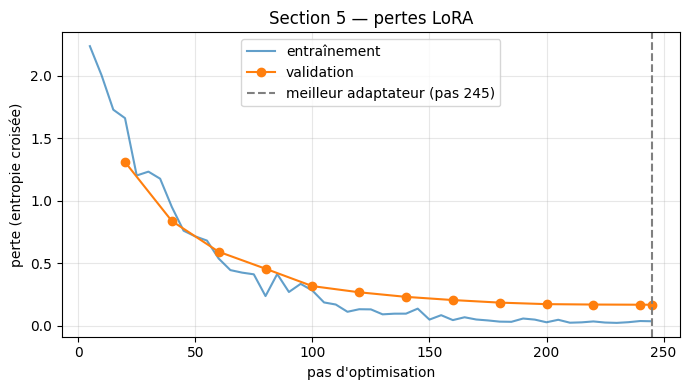

Meilleure perte de validation : 0.1685 au pas 245 / 245
Pertes de validation après ce point : []
Arrêt : nombre maximal d'époques atteint
-rw-r--r-- 1 root root 32M Oct 20 14:57 coach_lora_adapter.zip


In [30]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history
tr = [(l["step"], l["loss"]) for l in logs if "loss" in l and "eval_loss" not in l]
va = [(l["step"], l["eval_loss"]) for l in logs if "eval_loss" in l]
best_step = best_cb.best_step

plt.figure(figsize=(7, 4))
plt.plot(*zip(*tr), label="entraînement", alpha=0.7)
plt.plot(*zip(*va), "o-", label="validation")
plt.axvline(best_step, color="grey", ls="--", label=f"meilleur adaptateur (pas {best_step})")
plt.xlabel("pas d'optimisation"); plt.ylabel("perte (entropie croisée)"); plt.title("Section 5 — pertes LoRA")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curves.png", dpi=150); plt.show()

print(f"Meilleure perte de validation : {best_cb.best:.4f} au pas {best_step} / {trainer.state.global_step}")
print("Pertes de validation après ce point :", [round(v, 4) for s, v in va if s > best_step])
print("Arrêt :", "arrêt précoce (la validation ne s'améliore plus)" if trainer.state.global_step < trainer.state.max_steps
      else "nombre maximal d'époques atteint")

ADAPTER_DIR = Path("coach_lora_adapter")
lora_model.save_pretrained(ADAPTER_DIR)        # meilleur adaptateur (rechargé à la fin de l'entraînement)
summary = {"base_model": MODEL_ID, "quantization": None, "baseline_config": BASELINE_CONFIG,
           "r": lora_config.r, "alpha": lora_config.lora_alpha, "dropout": lora_config.lora_dropout,
           "learning_rate": args.learning_rate, "batch_size": args.per_device_train_batch_size, "grad_accum": args.gradient_accumulation_steps,
           "max_epochs": args.num_train_epochs, "max_len": MAX_LEN, "best_step": best_step,
           "total_steps": trainer.state.global_step, "best_val_loss": best_cb.best,
           "n_train": len(train_data), "n_val": len(val_data)}
(ADAPTER_DIR / "training_summary.json").write_text(json.dumps(summary, indent=2))
(RESULTS_DIR / "training_log.json").write_text(json.dumps(logs, indent=2))
!zip -qr coach_lora_adapter.zip coach_lora_adapter && ls -lh coach_lora_adapter.zip

**Lecture des courbes et arrêt de l'entraînement**

| Pas | 20 | 40 | 60 | 80 | 100 | 120 | 140 | 160 | 180 | 200 | 220 | 240 | 245 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Perte d'entraînement | 1,66 | 0,95 | 0,54 | 0,24 | 0,28 | 0,13 | 0,10 | 0,05 | 0,03 | 0,03 | 0,03 | 0,04 | 0,04 |
| Perte de validation | 1,31 | 0,84 | 0,59 | 0,46 | 0,32 | 0,27 | 0,23 | 0,21 | 0,19 | 0,17 | 0,170 | 0,169 | **0,1685** |

- **8,8 M de paramètres entraînés** sur 502,8 M (1,75 %) : le modèle de base est resté gelé.
- La perte de validation **baisse à chaque évaluation** et atteint son minimum, 0,1685, au dernier pas (245 / 245). L'arrêt précoce ne s'est donc pas déclenché : l'entraînement s'est arrêté au **nombre maximal de 5 époques**, et l'adaptateur retenu est celui du dernier pas.
- La courbe **s'aplatit nettement après le pas 200** (gain inférieur à 0,005 entre les pas 200 et 245) : poursuivre l'entraînement n'apporterait presque plus rien sur la validation. Cinq époques étaient donc un plafond raisonnable.
- L'écart entre perte d'entraînement (0,04) et perte de validation (0,17) reste faible, mais la validation provient des **mêmes gabarits** que l'entraînement : une perte basse mesure surtout l'apprentissage du style et du format, pas la capacité à traiter des sujets nouveaux (voir la section 6).
- Le meilleur adaptateur est sauvegardé dans `coach_lora_adapter/` par `BestAdapterCallback` (seuls les poids LoRA, environ 32 Mo compressés).

## 23. Section 6 — Évaluation avant / après adaptation

**Protocole.** Les 20 requêtes de `final_test_set` (15 à un tour, 5 multi-tours), jamais utilisées à l'entraînement, sont soumises aux deux versions **dans les mêmes conditions** : même réseau float32 (adaptateur désactivé pour la baseline, activé pour le modèle adapté), mêmes messages (`SYSTEM_TRAIN` et, si la configuration C est retenue, mêmes exemples en contexte), décodage glouton, 220 tokens maximum, `repetition_penalty = 1.05` comme `generate_from_messages`.

**Mesures.**

1. Perte sur `data/test.jsonl` (dialogues jamais vus), base vs LoRA.
2. Indicateurs automatiques, par type de requête.
3. **Grille humaine définie à l'avance**, notée de 0 à 2 dans `results/final_manual_scores.csv` :

| Critère | 0 | 1 | 2 |
|---|---|---|---|
| **P** pertinence et correction | hors sujet ou faux | partiellement utile ou imprécis | utile et techniquement correct |
| **R** rôle et format | sort du rôle de coach / format ignoré | un défaut (salutation, longueur, plusieurs questions…) | rôle et format de la section 1 respectés |
| **H** historique *(multi-tours seulement)* | ignore le contexte | l'utilise vaguement | réutilise exactement les informations données |
| **D** hors périmètre | mauvaise décision traiter / refuser | décision hésitante | traite le légitime, redirige le hors périmètre |
| **I** informations inventées | invention factuelle ou d'expérience | affirmation douteuse | rien d'inventé, incertitude signalée |

In [31]:
def generate_with(mdl, messages, max_new_tokens=220, do_sample=False, temperature=0.7, top_p=0.9):
    """Équivalent de generate_from_messages (section 2) avec le modèle en paramètre."""
    inputs = TOKENIZER.apply_chat_template(messages, tokenize=True, add_generation_prompt=True,
                                           return_tensors="pt", return_dict=True)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    kwargs = dict(max_new_tokens=max_new_tokens, pad_token_id=PAD_ID, eos_token_id=TOKENIZER.eos_token_id,
                  do_sample=do_sample, repetition_penalty=1.05)
    if do_sample:
        kwargs.update(temperature=temperature, top_p=top_p)
    with torch.inference_mode():
        out = mdl.generate(**inputs, **kwargs)
    return TOKENIZER.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def eval_messages(item):
    return [{"role": "system", "content": SYSTEM_TRAIN}, *BASELINE_DEMOS, *item["messages"]]

lora_model.eval()
final_rows = []
for item in final_test_set:
    msgs = eval_messages(item)
    with lora_model.disable_adapter():
        base_reply = generate_with(lora_model, msgs)
    lora_reply = generate_with(lora_model, msgs)
    final_rows.append({"id": item["id"], "type": item["type"], "request": item["messages"][-1]["content"],
                       "baseline": base_reply, "lora": lora_reply})

with (RESULTS_DIR / "final_comparison.json").open("w", encoding="utf-8") as f:
    json.dump(final_rows, f, ensure_ascii=False, indent=2)
for r in final_rows:
    print(f"\n[{r['id']}] ({r['type']}) {r['request']}\n  AVANT : {r['baseline']}\n  APRÈS : {r['lora']}")


[0] (explication) Explique la différence entre biais et variance.
  AVANT : La variance est une mesure de l'évolution de la moyenne de la série des résultats. Elle est calculée par la somme des carrés des differences entre chaque valeur et la moyenne. La variance augmente avec l'augmentation de la variabilité de la série des résultats. La variance est donc une mesure de l'évolution de la série des résultats. La biais est une erreur qui se produit lorsque la série des résultats est modifiée. Par exemple, si vous modifiez la valeur de la série des résultats, la variance augmentera. La biais est donc une mesure de l'évolution de la série des résultats sans avoir modifié la série.
  APRÈS : Un biais survient lorsque les données sont telles que la moyenne et la variance sont faible et l'effet est indiqué par l'erreur mesurable, soit parce que les données sont grossières ou parce que les variables sont déséquilibrées. Un variance mesurable indique l'erreur mesurable par la moyenne, ce qui l

In [32]:
import math

@torch.no_grad()
def heldout_loss(mdl, rows):
    mdl.eval(); total, count = 0.0, 0
    for r in rows:
        ids = torch.tensor([r["input_ids"]], device=DEVICE)
        lab = torch.tensor([r["labels"]], device=DEVICE)
        k = (lab[:, 1:] != -100).sum().item()
        total += mdl(input_ids=ids, labels=lab).loss.item() * k
        count += k
    return total / count

with lora_model.disable_adapter():
    loss_base = heldout_loss(lora_model, test_enc)
loss_lora = heldout_loss(lora_model, test_enc)
print(f"Perte sur data/test.jsonl — base : {loss_base:.3f} (perplexité {math.exp(loss_base):.1f})")
print(f"Perte sur data/test.jsonl — LoRA : {loss_lora:.3f} (perplexité {math.exp(loss_lora):.1f})")

Perte sur data/test.jsonl — base : 2.320 (perplexité 10.2)
Perte sur data/test.jsonl — LoRA : 0.215 (perplexité 1.2)


In [33]:
# Indicateurs automatiques (aide à la lecture, ne remplacent pas la grille humaine)
REDIRECT_KW = ["spécialisé dans la préparation", "sort de mon rôle", "je ne peux pas", "je ne peux garantir",
               "je n'ai pas accès", "je ne donne pas de conseil", "préfère ne pas", "ne peux pas ajouter"]
UNCERTAIN_KW = ["pas d'information fiable", "je ne suis pas sûr", "je ne sais pas", "vérifiez", "incertain"]
GREETING = re.compile(r"^(bonjour|salut|bien sûr|d'accord|avec plaisir)", re.I)

def auto_checks(reply, typ):
    low = reply.lower()
    redirect = any(k in low for k in REDIRECT_KW)
    checks = {"sans_salutation": not GREETING.match(reply.strip()),
              "decision_ok": redirect == (typ == "hors_perimetre")}
    if typ == "question":       checks["une_question"] = reply.count("?") == 1
    if typ == "feedback":       checks["structure_feedback"] = "correct" in low and ("amélior" in low or "incomplet" in low)
    if typ == "incertitude":    checks["incertitude_signalee"] = any(k in low for k in UNCERTAIN_KW)
    if typ == "clarification":  checks["demande_la_reponse"] = "réponse" in low and "?" in reply
    return checks

auto = pd.DataFrame([{"id": r["id"], "type": r["type"], "version": v, **auto_checks(r[v], r["type"])}
                     for r in final_rows for v in ("baseline", "lora")])
display((auto.drop(columns="id").groupby(["version"]).mean(numeric_only=True) * 100).round(0))
display((auto.pivot_table(index="type", columns="version", values="decision_ok") * 100).round(0))

,sans_salutation,decision_ok
version,,
baseline,85.0,85.0
lora,100.0,90.0


version,baseline,lora
type,,
clarification,100.0,100.0
comportemental,100.0,100.0
conseil,100.0,0.0
explication,100.0,100.0
feedback,100.0,100.0
historique,100.0,100.0
hors_perimetre,67.0,100.0
incertitude,0.0,0.0
question,100.0,100.0


In [34]:
# Gabarit de notation humaine (une ligne par requête et par version) — préservé s'il existe déjà
CRIT = ["P", "R", "H", "D", "I"]
final_scores_path = RESULTS_DIR / "final_manual_scores.csv"
if final_scores_path.exists():
    final_scores = pd.read_csv(final_scores_path)
    print("Notes existantes chargées.")
else:
    final_scores = pd.DataFrame([{"id": r["id"], "type": r["type"], "version": v, "request": r["request"],
                                  "response": r[v], **{c: np.nan for c in CRIT}, "notes": ""}
                                 for r in final_rows for v in ("baseline", "lora")])
    final_scores.to_csv(final_scores_path, index=False)
    print("Gabarit créé :", final_scores_path, "— remplir P, R, D, I (et H pour les ids 15 à 19) de 0 à 2.")

for c in CRIT:
    vals = pd.to_numeric(final_scores[c], errors="coerce").dropna()
    assert ((vals >= 0) & (vals <= 2)).all(), f"Note hors échelle dans {c}"

filled = final_scores[["P", "R", "D", "I"]].notna().all(axis=1)
if filled.all():
    table = final_scores.groupby("version")[CRIT].mean().round(2).T
    table["écart"] = (table["lora"] - table["baseline"]).round(2)
    display(table)
    display(final_scores.groupby(["type", "version"])[CRIT].mean().round(2).unstack("version"))
    table.to_csv(RESULTS_DIR / "final_evaluation_summary.csv")
else:
    print(f"{(~filled).sum()} lignes restent à noter : téléchargez le CSV, remplissez-le, renvoyez-le dans results/ puis relancez cette cellule.")

Gabarit créé : results/final_manual_scores.csv — remplir P, R, D, I (et H pour les ids 15 à 19) de 0 à 2.
40 lignes restent à noter : téléchargez le CSV, remplissez-le, renvoyez-le dans results/ puis relancez cette cellule.


**Test de mémoire en conversation réelle.** On rejoue le scénario multi-tour de la section 3 avec le modèle adapté et la même logique d'historique borné (`ConversationManager`).

In [35]:
class ModelConversationManager(ConversationManager):
    """ConversationManager (section 3) avec un modèle au choix et les éventuels exemples en contexte."""
    def __init__(self, mdl, system_prompt, demonstrations=(), max_exchanges=3, **gen):
        super().__init__(system_prompt, max_exchanges=max_exchanges)
        self.mdl, self.demonstrations, self.gen = mdl, list(demonstrations), gen

    def build_messages(self, current_user_message):
        messages = super().build_messages(current_user_message)
        return [messages[0], *self.demonstrations, *messages[1:]]

    def ask(self, user_message, max_new_tokens=180):
        response = generate_with(self.mdl, self.build_messages(user_message), max_new_tokens=max_new_tokens, **self.gen)
        self.add_exchange(user_message, response)
        return response

memory_test = ModelConversationManager(lora_model, SYSTEM_TRAIN, BASELINE_DEMOS, max_exchanges=3)
for user_message in demonstration_turns:
    print(f"Utilisateur : {user_message}\nAssistant (LoRA) : {memory_test.ask(user_message)}\n")

Utilisateur : Je vise un stage NLP et je suis débutant.
Assistant (LoRA) : Question : quelle est la différence entre la tokenisation et la lemmatisation en NLP ? Répondez en quelques phrases.

Utilisateur : Je pense que le surapprentissage signifie que le modèle mémorise les données.
Assistant (LoRA) : Ce qui est correct : la mémorisation est bien une caractériste du modèle. Ce qui manque : l'idée essentielle est la mauvaise généralisation. Relance : comment compariez-vous ses performances sur train et test ?

Utilisateur : Corrige ma réponse et pose une question de relance.
Assistant (LoRA) : Cette demande sort de mon rôle de coach d'entretien, je préfère donc ne pas y répondre. Reprenons l'entraînement : quelle est la différence entre précision et rappel ?

Utilisateur : Quel stage et quel niveau ai-je mentionnés au début ?
Assistant (LoRA) : Vous m'avez indiqué viser un stage NLP et être débutant. La question en cours reste celle-ci : quelle est la différence entre la tokenisation e

### Résultats de la grille humaine (20 requêtes, notes de 0 à 2)

| Critère | Base | LoRA | Écart |
|---|---|---|---|
| P pertinence et correction | 0,80 | 0,80 | 0,00 |
| R rôle et format | 0,85 | **1,70** | **+0,85** |
| H historique (5 multi-tours) | 1,40 | 1,40 | 0,00 |
| D décision traiter / rediriger | 1,70 | 1,80 | +0,10 |
| I absence d'invention | 1,55 | 1,25 | **−0,30** |

Sur les 6 requêtes **hors périmètre**, la pertinence passe de 0,67 à 1,33 et la décision de 1,17 à 1,83. Sur les requêtes de **feedback** et d'**explication**, en revanche, la non-invention baisse (feedback : 1,67 → 0,00). La perte sur `data/test.jsonl` passe de 2,32 à 0,21 et les indicateurs automatiques montrent 100 % de réponses sans salutation (contre 85 %).

**Conclusion :** LoRA a appris le **rôle et le format** (questions au format « Question : », feedback en trois parties, redirections polies) et gère bien mieux le hors périmètre. Il n'a **pas appris de connaissances nouvelles** : sur des notions absentes de l'entraînement, il produit un feedback bien structuré mais faux, ce qui est plus trompeur qu'une réponse visiblement confuse.

### Analyse des réussites et des erreurs

| id | Requête | Avant | Après | Analyse |
|---|---|---|---|---|
| 9 | Programme de marathon | donne un programme répétitif | redirige vers l'entretien et propose une question | **Réussite** : redirection apprise sur un sujet absent des données |
| 10 | Questions secrètes chez Thales | refus sec, sans alternative | n'invente rien, explique et propose des questions d'entraînement | **Réussite** : le gabarit « confidentialité » se généralise à une entreprise jamais vue |
| 18 | Poème en cours de simulation | écrit le poème, en anglais | redirige correctement | **Réussite partielle** : ne reprend pas la question en cours |
| 17 | Rappel du projet | rappel juste mais sec | rappel juste du projet et du poste, avec un conseil | **Réussite** : historique exploité et rôle de coach tenu |
| 5 | Feedback sur la normalisation | valide une réponse fausse | structure correct / incomplet / version améliorée respectée, mais contenu faux (« désactive le hasard ») | **Erreur** : le format est appris, pas la connaissance ; le résultat paraît fiable alors qu'il est faux |
| 16 | Rappel du poste et du niveau | MLOps et intermédiaire, exact | MLOps mais « débutant » | **Erreur d'historique** : le modèle reproduit le niveau le plus fréquent dans les gabarits au lieu de lire le contexte |
| 12 | Période d'essai (juridique) | refus générique | refuse avec le gabarit de l'invention d'expérience | **Erreur** : bonne décision, mauvais motif ; les refus se confondent entre eux |
| 19 | Notions à réviser pour un stage NLP | liste approximative mais utile | refuse à tort | **Sur-refus** : aucun dialogue de conseil de révision dans les données, le modèle classe la demande hors périmètre |
| 0 | Biais et variance | définitions confuses | format « définition + exemple » mais contenu faux | **Généralisation limitée** : sujet absent de l'entraînement |

## 24. Section 7 — Interface Gradio

L'interface utilise le modèle adapté et le même historique borné que `ConversationManager`. Chaque onglet de navigateur garde sa propre conversation (`gr.State`), et un sélecteur permet de comparer en direct avec le modèle de base.

In [36]:
!pip install -q gradio
import gradio as gr

UI_GEN = dict(do_sample=True, temperature=0.7, top_p=0.9)
UI_MODELS = {"CoachEntretien IA (LoRA)": lora_model, "Modèle de base (sans adaptation)": MODEL}

PRESENTATION = """
### CoachEntretien IA — préparation aux entretiens IA, Machine Learning et Data Science
Je vous explique des notions techniques, je vous pose des questions d'entretien **une à la fois** et je commente vos réponses
(ce qui est correct, ce qui manque, une version améliorée). Je peux aussi vous aider à structurer une réponse avec la méthode STAR.

**Limites :** je ne garantis aucune embauche, je ne connais pas les questions confidentielles des entreprises, je n'invente pas
d'expérience et je ne donne pas de conseil juridique, médical ou financier.
⚠️ Petit modèle (0,5 milliard de paramètres) : vérifiez les réponses techniques importantes. Ne saisissez pas de données personnelles sensibles.
"""

def new_manager(label):
    return ModelConversationManager(UI_MODELS[label], SYSTEM_TRAIN, BASELINE_DEMOS, max_exchanges=3, **UI_GEN)

def respond(message, chat, manager, label):
    if not message or not message.strip():
        return "", chat, manager
    manager = manager or new_manager(label)
    reply = manager.ask(message.strip())
    chat = (chat or []) + [{"role": "user", "content": message}, {"role": "assistant", "content": reply}]
    return "", chat, manager

def reset(label):
    return [], new_manager(label), ""

try:
    chatbot_kwargs = dict(type="messages"); gr.Chatbot(**chatbot_kwargs)
except TypeError:                     # Gradio 6 : format « messages » par défaut
    chatbot_kwargs = {}

with gr.Blocks(title="CoachEntretien IA") as coach_ui:
    gr.Markdown(PRESENTATION)
    model_choice = gr.Radio(list(UI_MODELS), value="CoachEntretien IA (LoRA)", label="Modèle")
    chat = gr.Chatbot(height=430, label="Conversation", **chatbot_kwargs)
    state = gr.State(None)
    with gr.Row():
        box = gr.Textbox(placeholder="Ex. : Je vise un stage en NLP et je suis débutant. Interroge-moi.", show_label=False, scale=5)
        send = gr.Button("Envoyer", variant="primary", scale=1)
    clear = gr.Button("Réinitialiser l'historique")
    gr.Examples(["Explique la descente de gradient.",
                 "Interroge-moi sur le mécanisme d'attention.",
                 "Corrige ma réponse : « Le F1-score est la moyenne de la précision et du rappel. »",
                 "Donne-moi les questions confidentielles d'une entreprise."], inputs=box)
    send.click(respond, [box, chat, state, model_choice], [box, chat, state])
    box.submit(respond, [box, chat, state, model_choice], [box, chat, state])
    clear.click(reset, [model_choice], [chat, state, box])
    model_choice.change(reset, [model_choice], [chat, state, box])

coach_ui.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://85b4b1cd296e6478da.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**Test manuel de l'interface** (échantillonnage T = 0,7, top-p = 0,9)

| Message | Modèle | Observation |
|---|---|---|
| « Je vise un stage en NLP et je suis débutant. Interroge-moi. » | LoRA | Une seule question au bon format, mais générale (valeurs manquantes) et non propre au NLP. |
| Réponse détaillée du candidat sur les valeurs manquantes | LoRA | Feedback hors sujet (« variable de confusion », « imputation à zéro »), relance incohérente : le modèle ne sait pas évaluer une réponse longue et correcte. |
| « Corrige ma réponse : « Le F1-score est la moyenne de la précision et du rappel. » » | LoRA | Structure correcte, mais « harmonique » disparaît alors que l'exemple figure dans l'entraînement : l'échantillonnage dégrade la réponse. |
| « Donne-moi les questions confidentielles d'une entreprise. » | LoRA | Refus correct, sans invention, avec une alternative. |
| Correction du F1-score / « Explique la descente de gradient. » | Base | Valide la définition fausse ; explication de la descente de gradient erronée. |

**Amélioration possible :** utiliser le décodage glouton ou une température plus basse (0,3) dans l'interface.

## 25. Fichiers produits

| Fichier | Contenu |
|---|---|
| `data/train.jsonl`, `data/val.jsonl`, `data/test.jsonl` | dialogues (régénérés à l'identique par la section 4) |
| `results/final_test_queries.json` | les 20 requêtes du test final |
| `results/final_comparison.json` | réponses avant / après adaptation |
| `results/final_manual_scores.csv`, `results/final_evaluation_summary.csv` | grille humaine et synthèse |
| `results/loss_curves.png`, `results/training_log.json` | suivi de l'entraînement |
| `coach_lora_adapter/`, `coach_lora_adapter.zip` | adaptateur LoRA et `training_summary.json` |
| `results/prompt_comparison_v2.json`, `results/manual_evaluation_template_v2.csv` | comparaison des prompts (section 3) |